# Семинар 5. Регуляризация. Метрики качества.

**Сюжет семинара:** На заводе есть цех со станками, и на каждом станке стоят датчики (вибрация, температура подшипника, нагрузка и т.д.). С помощью этих данных мы будем решать две задачи:

1. **Регрессия** — по показаниям датчиков предсказывать *износ подшипника*. Датчиков много, часть из них дублирует друг друга, часть — просто шум. Здесь нам понадобится **регуляризация** (и немного оптимизации, чтобы понять, как решается LASSO).
2. **Классификация** — решать, *исправен станок или нет*. Здесь разберём **метрики качества**: почему нельзя ограничиться accuracy, что такое precision / recall / ROC / PR.

Два побочных сюжета появятся там, где станков не хватает: *научные статьи* (очень редкий положительный класс) и *склад запчастей* (метрики для регрессии на данных разного масштаба).

**План.**
- Регуляризация: зачем она нужна, Ridge, LASSO, ElasticNet
- Минутка оптимизации: субградиент, прокс-оператор, ISTA/FISTA
- Регуляризация как отбор признаков
- Подбор параметра регуляризации в scikit-learn
- Метрики: классификация (accuracy, confusion matrix, precision/recall, ROC, PR, log-loss, multiclass), регрессия (MSE, MAE, R², MAPE и родственники)

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                  RidgeCV, LassoCV, ElasticNetCV)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

np.set_printoptions(precision=3, suppress=True, linewidth=120)
pd.options.display.float_format = "{:.3f}".format
plt.rcParams.update({"axes.grid": True, "figure.figsize": (7, 4), "figure.dpi": 100})

## Регуляризация

Модель линейной регрессии:

$$a(X_1, ... , X_n) = w_0 + w_1 X_1 + ... + w_n X_n = x^T w$$

$$w = (w_0, w_1, ... , w_n)^T$$

$$x = (X_0, X_1, ... , X_n)^T, \text{где $X_0 = 1$ - фиктивный признак}$$

Обучение по выборке:
- ${(x_1, y_1), (x_2, y_2), ... , (x_m, y_m)}, x_i \in \mathbb{R}^{n+1}$

Дает систему:

\begin{equation*}
 \begin{cases}
   x_1^Tw = y_1\\
   ... \\
   x_m^T w = y_m
 \end{cases}
 \Leftrightarrow Xw = y
\end{equation*}

$$L(w) = \|Xw - y \|_2^2 \rightarrow \min_w$$

$$\|Xw - y \|_2^2 = (Xw - y)^T(Xw - y) = w^T X^T X w - w^TX^Ty - y^TXw + y^Ty$$

$$\nabla \|Xw - y \|_2^2 = 2X^T Xw - 2X^T y = 0 \Rightarrow w = (X^TX)^{-1}X^T y$$
- Решение в матричной форме существует, если столбцы линейно независимые.

Один из способов борьбы с вырожденностью — **регуляризация**. Это метод добавления некоторых дополнительных ограничений к условию с целью решить некорректно поставленную задачу или предотвратить переобучение. Чаще всего эта информация имеет вид штрафа за сложность модели.

### Зачем это нужно: переобучение

Вырожденная матрица — не единственная беда. Посмотрим на простой пример. Для 15 станков измерили (нормированную) температуру подшипника $x$ и износ $y$. Зависимость нелинейная, измерения шумные. Мы хотим подогнать полином степени 12 — «чем богаче модель, тем лучше, правда?»

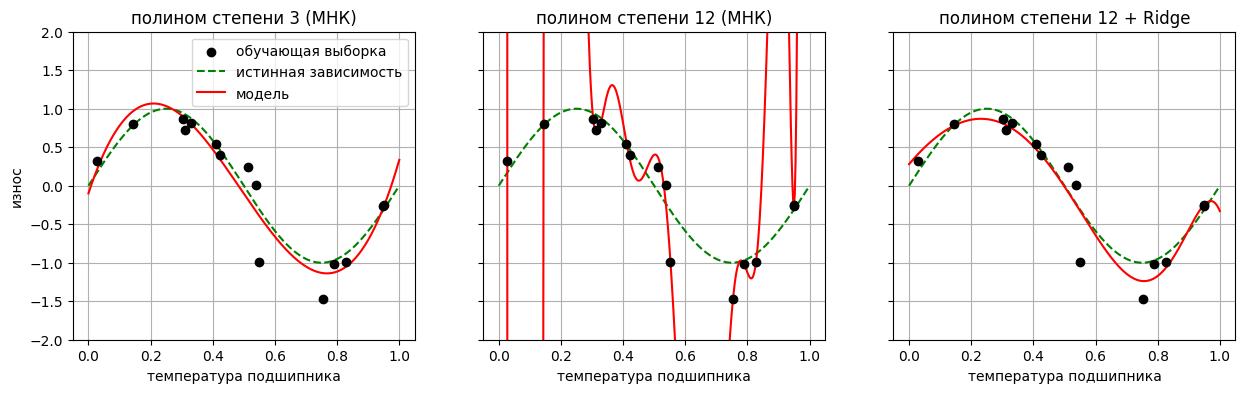

,MSE train,MSE test,max |w|
модель,,,
полином степени 3 (МНК),0.0573,0.0837,11.1
полином степени 12 (МНК),0.00855,5.74e+04,1.19e+09
полином степени 12 + Ridge,0.0492,0.0842,2.46


In [2]:
rng = np.random.default_rng(1)

def true_wear(t):
    return np.sin(2 * np.pi * t)        # "настоящая" гладкая зависимость (нам она неизвестна)

x_tr = np.sort(rng.uniform(0, 1, 15));  y_tr = true_wear(x_tr) + rng.normal(0, 0.25, 15)
x_te = np.sort(rng.uniform(0, 1, 500)); y_te = true_wear(x_te) + rng.normal(0, 0.25, 500)
x_grid = np.linspace(0, 1, 400)

def poly_model(degree, regressor):
    # StandardScaler нужен, чтобы x, x^2, ..., x^12 были в сравнимых масштабах
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), regressor)

models = {
    "полином степени 3 (МНК)":        poly_model(3,  LinearRegression()),
    "полином степени 12 (МНК)":       poly_model(12, LinearRegression()),
    "полином степени 12 + Ridge":     poly_model(12, Ridge(alpha=0.01)),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
rows = []
for ax, (name, model) in zip(axes, models.items()):
    model.fit(x_tr[:, None], y_tr)
    ax.scatter(x_tr, y_tr, c="k", zorder=3, label="обучающая выборка")
    ax.plot(x_grid, true_wear(x_grid), "g--", label="истинная зависимость")
    ax.plot(x_grid, model.predict(x_grid[:, None]), "r", label="модель")
    ax.set_ylim(-2, 2); ax.set_title(name); ax.set_xlabel("температура подшипника")
    rows.append({"модель": name,
                 "MSE train": np.mean((model.predict(x_tr[:, None]) - y_tr) ** 2),
                 "MSE test":  np.mean((model.predict(x_te[:, None]) - y_te) ** 2),
                 "max |w|":   np.abs(model[-1].coef_).max()})
axes[0].set_ylabel("износ"); axes[0].legend()
plt.show()
pd.DataFrame(rows).set_index("модель").style.format("{:.3g}")

Полином степени 12 «проходит» через все 15 точек (ошибка на обучении почти ноль), но между точками он болтается как хочет, а на новых данных ошибка огромна. Обратите внимание на **веса**: у обычного МНК они порядка $10^9$, у Ridge — порядка единицы, и при этом качество на новых данных у Ridge сравнимо с «правильным» полиномом степени 3.

Посмотрим, как ошибка зависит от силы регуляризации $\lambda$ (в sklearn она называется `alpha`).

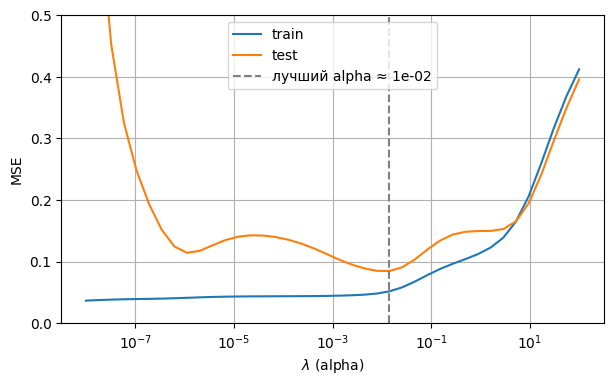

In [3]:
alphas = np.logspace(-8, 2, 40)
train_err, test_err = [], []
for a in alphas:
    m = poly_model(12, Ridge(alpha=a)).fit(x_tr[:, None], y_tr)
    train_err.append(np.mean((m.predict(x_tr[:, None]) - y_tr) ** 2))
    test_err.append(np.mean((m.predict(x_te[:, None]) - y_te) ** 2))

best = alphas[np.argmin(test_err)]
plt.semilogx(alphas, train_err, label="train")
plt.semilogx(alphas, test_err, label="test")
plt.axvline(best, color="gray", ls="--", label=f"лучший alpha ≈ {best:.0e}")
plt.ylim(0, 0.5)
plt.xlabel(r"$\lambda$ (alpha)"); plt.ylabel("MSE"); plt.legend(); plt.show()

- **Слева** ($\lambda \to 0$) — переобучение: модель подгоняется под шум.
- **Справа** ($\lambda$ велико) — недообучение: веса так сильно «прижаты» к нулю, что модель не может описать даже настоящую зависимость.
- **Посередине** — разумный компромисс. Кривая test-ошибки U-образная, а $\lambda$ — типичный **гиперпараметр**: его выбирают по валидации (вспоминаем семинар 4).

#### **Интуиция**

Представим, что у нас есть модель линейной регрессии: $a(X_1, ... , X_n) = w_0 + w_1 X_1 + ... + w_n X_n$, а в обучающей выборке есть $2$ похожих объекта (два почти одинаковых станка), которые различаются на $j$-ом признаке на малую величину $\varepsilon_j$. Тогда и ответы модели на них будут отличаться на $\varepsilon_j w_j$.

Если вес $w_j$ огромный, то крошечный шум в датчике превращается в огромную разницу в предсказании. Это ровно то, что мы видели на графике выше.

$\rightarrow$ вместе с $\|Xw - y \|_2^2 \rightarrow \min_w$ хотим некоторым образом **минимизировать веса** $w$ модели.

### Ridge Regression. Регуляризация Тихонова.

$$L_2(w) = \| Xw - y \|_2^2 + \lambda \| w \|_2^2 \rightarrow \min$$

$$\nabla L_2(w) = 2X^T Xw - 2X^T y + 2 \lambda w = 0$$

$$w = (X^T X + \lambda I)^{-1} X^T y$$

- борется с вырожденностью матрицы: у $X^TX$ собственные значения $\ge 0$ (какие-то могут быть нулевыми), а у $X^TX + \lambda I$ все собственные значения $\ge \lambda > 0$, поэтому матрица всегда обратима
- при $\lambda = 0$ получаем классическое решение
- при $\lambda \rightarrow + \infty$ меньше затачиваемся под данные, больше регуляризируем (веса стремятся к нулю)
- свободный член $w_0$ обычно **не штрафуют** (в sklearn так и сделано): сдвиг всех ответов на константу не усложняет модель

### LASSO Regression.

$$L_1(w) = \| Xw - y \|_2^2 + \lambda \| w \|_1 \rightarrow \min$$

- регуляризатор не является гладкой функцией (у $|w|$ «излом» в нуле), поэтому в общем случае формулы вроде $w = (X^TX + \lambda I)^{-1}X^Ty$ не получить
- зато у LASSO есть замечательное свойство: часть весов оказывается **ровно нулём** (разберём чуть позже)

Тут же отметим, что и для МНК, и для регуляризации Тихонова аналитическое решение — не всегда лучший вариант:

- Вычислительная сложность аналитического решения: $O(n^2 \cdot m + n^3)$, где $m$ — длина выборки, $n$ — число признаков у одного объекта.
- Матрица $X^TX$, хотя почти всегда обратима в разумных задачах машинного обучения, зачастую плохо обусловлена. Особенно если признаков много, между ними может появляться приближённая линейная зависимость, которую мы можем упустить на этапе формулировки задачи. Это делает полученное таким образом решение численно неустойчивым: малые возмущения $y$ могут приводить к катастрофическим изменениям $w$.

Сначала сравним скорость двух подходов, а потом разберёмся, что на самом деле значит «плохо обусловлена».

### Аналитическое решение или градиентный спуск?

Сравним **скорость поиска решения** двумя способами. Для градиентного спуска нам нужен шаг $1/L$, где $L$ — константа гладкости; для квадратичной функции $L$ — наибольшее собственное значение гессиана, его можно оценить за несколько умножений матрицы на вектор (степенной метод).

Вместо `inv(X.T @ X) @ ...` используйте `np.linalg.solve` — решать систему устойчивее и быстрее, чем явно обращать матрицу.

In [4]:
def lipschitz(X, lam=0.0, n_iter=30, seed=0):
    """Наибольшее собственное значение гессиана функции (1/m)(||Xw-y||^2 + lam||w||^2)."""
    v = np.random.default_rng(seed).standard_normal(X.shape[1])
    for _ in range(n_iter):
        v = X.T @ (X @ v)
        v /= np.linalg.norm(v)
    return 2 * (v @ (X.T @ (X @ v)) + lam) / X.shape[0]


def grad_desc(X, y, lam=0.0, tol=1e-4, max_iter=500):
    """Градиентный спуск для (1/m)(||Xw-y||^2 + lam*||w||^2)
    Останавливаемся, когда норма градиента меньше tol."""
    m, n = X.shape
    step = 1 / lipschitz(X, lam)
    w = np.zeros(n)
    for k in range(max_iter):
        grad = 2 * (X.T @ (X @ w - y) + lam * w) / m
        if np.linalg.norm(grad) < tol:
            return w, k, True
        w -= step * grad
    return w, max_iter, False

In [5]:
M, N = 20000, 800
rng = np.random.default_rng(0)
X = rng.standard_normal((M, N))
w_true = rng.standard_normal(N)
y = X @ w_true

t = time.perf_counter()
w_analytical = np.linalg.solve(X.T @ X, X.T @ y)
t_analytical = time.perf_counter() - t

t = time.perf_counter()
w_gd, n_iter, ok = grad_desc(X, y)
t_gd = time.perf_counter() - t

print(f"аналитика:  {t_analytical:.2f} c, ошибка {np.linalg.norm(w_analytical - w_true):.1e}")
print(f"град. спуск: {t_gd:.2f} c, {n_iter} итераций, ошибка {np.linalg.norm(w_gd - w_true):.1e}")

аналитика:  0.09 c, ошибка 6.1e-14
град. спуск: 0.51 c, 18 итераций, ошибка 6.0e-05


Неожиданно? **На таком размере аналитическое решение быстрее.** Градиентный спуск тоже сошёлся быстро (десятки итераций), но этих итераций всё равно достаточно, чтобы потратить столько же времени. Так что утверждение «градиентный спуск быстрее» нужно понимать правильно:

- цена аналитики $\sim m n^2 + n^3$ (один раз), цена одной итерации спуска $\sim m n$. Спуск выигрывает, когда число итераций **заметно меньше $n$**, то есть когда признаков действительно много (в большом эксперименте ниже при $m = 5\cdot10^5$, $n = 2000$ аналитика считалась порядка минуты, а спуск — на порядок быстрее);
- число итераций зависит от **обусловленности** матрицы $X^TX$. Что это такое — ниже.

*Для любителей больших цифр* — ($m = 500\,000$, $n = 2000$, ~20+ ГБ памяти):

In [6]:
RUN_BIG = False       # воспроизвести большой эксперимент

if RUN_BIG:
    M, N = 500000, 1999
    X = np.random.randn(M, N)
    X = np.hstack((X, np.ones((M, 1))))
    w = np.random.randn(N+1)
    y = X @ w

In [9]:
%%timeit

(np.linalg.inv(X.T @ X)@X.T@y)
# 1min 11s ± 3.82 s per loop (mean ± std. dev. of 7 runs, 1 loop each)

1min 11s ± 3.82 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [7]:
%%timeit

grad_desc(X, y)
# 25.8 s ± 832 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)

25.8 s ± 832 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


#### ''Число обусловленности''

Представьте функцию потерь $\|Xw - y\|^2$ как «долину», а её линии уровня — как эллипсы вокруг минимума. Форму этих эллипсов задаёт матрица $X^TX$: её собственные значения показывают, насколько круто стенки долины поднимаются в разных направлениях.

<div style="text-align:center">
<img src="src/c_level.png" width="350px">
</div>

- **Хорошая обусловленность.** Долина «круглая»: во всех направлениях стенки поднимаются примерно одинаково, антиградиент смотрит почти прямо на минимум — спуск доходит за считанные шаги. Именно так устроена случайная гауссовская матрица из примера выше.
- **Плохая обусловленность.** Долина превращается в **длинный узкий овраг**: поперёк стенки крутые, вдоль дно почти плоское. Антиградиент смотрит в основном на крутую стенку, а не вдоль оврага, поэтому спуск «прыгает» от стенки к стенке и очень медленно ползёт по дну. Шаг при этом нельзя брать большим (иначе перепрыгнем через овраг), так что вдоль пологого направления мы двигаемся крошечными шагами.

**Число обусловленности** $\kappa = \lambda_{max}/\lambda_{min}$ — это отношение крутизны самого крутого направления к крутизне самого пологого, то есть «во сколько раз овраг длиннее, чем шире». $\kappa \approx 1$ — круг, $\kappa = 10^6$ — очень вытянутый овраг. Число итераций градиентного спуска растёт примерно как $\kappa \cdot \log(1/\varepsilon)$ (это то же самое $L/\mu$ из теоремы про сходимость ниже).

**Откуда берётся плохая обусловленность?** Из почти линейно зависимых признаков. Если два датчика показывают почти одно и то же, то можно увеличить вес первого и на столько же уменьшить вес второго — и предсказания почти не изменятся. Значит, вдоль этого направления дно долины почти плоское ($\lambda_{min} \approx 0$, а $\kappa$ огромно).

Из этого вырастают **две беды**:

1. **Медленная сходимость:** градиентный спуск ползёт вдоль плоского дна.
2. **Неустойчивость решения:** вдоль плоского дна очень разные $w$ дают почти одинаковую ошибку, поэтому крошечный шум в измерениях $y$ может «перебросить» минимум далеко вдоль оврага. Веса резко меняются при малейшем изменении данных, хотя предсказания остаются почти прежними.

**Как помогает Ridge.** Добавка $\lambda I$ сдвигает **все** собственные значения матрицы на $\lambda$:

$$\kappa(X^TX + \lambda I) = \frac{\lambda_{max} + \lambda}{\lambda_{min} + \lambda}$$

Если $\lambda_{min}$ было почти нулём, то в знаменателе теперь стоит $\approx \lambda$, и $\kappa$ падает с огромного до порядка $\lambda_{max}/\lambda$. Геометрически: дно оврага «приподнимается», эллипсы становятся круглее. Спуск сходится быстрее, а решение перестаёт прыгать от шума. Платим за это смещением решения: чем больше $\lambda$, тем дальше мы от «чистого» МНК. Заодно $X^TX + \lambda I$ всегда обратима.

Для **Ridge-регрессии** тоже имеет смысл использовать градиентный спуск. Но что делать для решения **LASSO-регрессии**, где градиента нет? Об этом — следующий раздел.

### Минутка оптимизации.

**Задача.** Хотим минимизировать $\|Xw - y\|_2^2 + \lambda \|w\|_1$. Первое слагаемое гладкое, второе — нет. Что мы умеем?

- аналитическое решение — нет (в общем случае);
- градиентный спуск — не применим, у $|w|$ в нуле нет градиента;
- **субградиентный спуск** — применим, но медленный;
- вероятно, получится придумать что-то специальное под сумму «гладкое + негладкое» — это **проксимальный градиентный метод**.

#### Субдифференциальные исчисления.

**Идея.** У гладкой выпуклой функции в каждой точке есть касательная, и весь график лежит выше неё. У $|x|$ в нуле касательной нет, но можно провести *много* прямых через $(0, 0)$, под которыми лежит график. Угловые коэффициенты таких прямых и называют субградиентами.

**Опр 1.** Пусть дана функция $f: \mathbb{R}^d \rightarrow \mathbb{R}$ и точка $x_0 \in \mathbb{R}^d$. Точка $z \in \mathbb{R}^d$ называется субградиентом функции $f$ в точке $x_0$ , если для всех $x \in \mathbb{R}^d$ выполнено:
$$f(x) \ge f(x_0) + \langle z, x − x_0 \rangle$$

**Опр 2.** Множество всех субградиентов функции $f$ в точке $x_0$ называется субдифференциалом функции в точке $x_0$ , будем обозначать его $\partial f(x_0)$.

--------------------------------

**Пример.** Пусть $f: \mathbb{R} → \mathbb{R}$ функция $f(x) = |x|$. Тогда $\partial f(0) = [−1, 1]$.

*Доказательство.* Пусть $z\in [−1, 1]$. Тогда $zx \le |z||x| ≤ |x|$ для всех $x \in \mathbb{R}$, т. е., по определению, $z \in \partial f(0)$. В силу произвольности $z$, это означает, что $[−1, 1] ⊆ \partial f(0)$. Остается показать, что вложение, на самом деле, является равенством.

Предположим, чтобы прийти к противоречию, что найдется $z \in \partial f(0)$, такое, что $|z| > 1$. Тогда, по определению субградиента, $|x| \ge zx$ для всех $x \in \mathbb{R}$. Полагая $x = z$, получаем $|z| \ge |z|^2$, что невозможно.

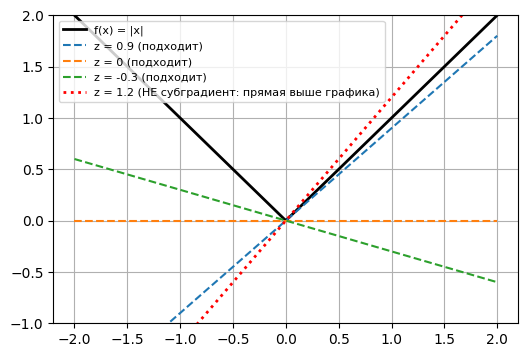

In [6]:
x = np.linspace(-2, 2, 1000)
plt.figure(figsize=(6, 4))
plt.plot(x, np.abs(x), "k", lw=2, label="f(x) = |x|")
plt.plot(x, 0.9 * x,  "--", label="z = 0.9 (подходит)")
plt.plot(x, 0 * x,    "--", label="z = 0 (подходит)")
plt.plot(x, -0.3 * x, "--", label="z = -0.3 (подходит)")
plt.plot(x, 1.2 * x,  "r:", lw=2, label="z = 1.2 (НЕ субградиент: прямая выше графика)")
plt.ylim(-1, 2); plt.legend(fontsize=8); plt.show()

Все прямые с наклоном из $[-1, 1]$ лежат под графиком, а прямая с наклоном $1.2$ с правой стороны от нуля графика не касается и пересекает его, поэтому $1.2 \notin \partial f(0)$.

**Утв. 1.** (Субдифференциал дифференцируемой функции) Пусть $f: \mathbb{R}^d \rightarrow \mathbb{R}$, $f$ — дифференцируема в точке $x_0 \in \mathbb{R}^d$. Тогда либо $\partial f(x_0) = \emptyset$, либо $\partial f(x_0) = \{ \nabla f(x_0) \}$. Если $f$ — выпукла, то $f$ — дифференцируема в точке $x_0$ тогда и только тогда, когда $\partial f(x_0) = \{ \nabla f(x_0) \}$

**Утв. 2.** (Критерий минимума) Пусть $f: \mathbb{R}^d \rightarrow \mathbb{R}$ выпукла. Точка $x_0 \in \mathbb{R}^d$ — (глобальный) минимум функции тогда и только тогда, когда $0 \in \partial f(x_0)$.

(Для $|x|$: $0 \in \partial f(0) = [-1, 1]$, и правда, ноль — минимум. Запомним этот приём — он понадобится при выводе прокс-оператора.)

Понятие субдифференциала позволяет использовать метод **субградиентного спуска** для выпуклых, но негладких задач оптимизации:

$$x_{k+1} = x_k - \alpha_k g^k(x_k)$$

где $g^k \in \partial f(x_k)$ - любой из субградиентов функции $f$ в точке $x_k$.

***В самом общем случае*** это (и его производные) единственный метод, который можно использовать для решения негладких выпуклых задач. Однако он имеет ***низкую скорость сходимости***: ошибка падает как $O(1/\sqrt{k})$ против $O(1/k)$ у метода, который мы сейчас изучим. Кроме того (это мы увидим на эксперименте), он не умеет давать **точные нули** в весах.

### Проксимальный метод.

**Идея на пальцах.** Функция $f(w) + r(w)$ состоит из «хорошей» гладкой части $f$ (у неё есть градиент) и «плохой» негодной части $r$ (негладкая, как $\lambda\|w\|_1$). Будем делать два шага по очереди:

1. шаг градиентного спуска по $f$ (как обычно);
2. «подтяжка» по $r$: сдвигаем точку так, чтобы уменьшить $r$, но не уйти слишком далеко от текущей точки. Эта подтяжка называется *проксимальным оператором*.

Теперь аккуратно. Рассмотрим обратную схему Эйлера (неявный шаг — градиент берём в **новой** точке):

$$\frac{x_{k+1} - x_k}{\alpha} = - \nabla f(x_{\color{red}{k+1}})$$

$$\frac{x_{k+1} - x_k}{\alpha} + \nabla f(x_{k+1}) = 0$$

$$\nabla \left [ \dfrac{1}{2 \alpha } \| x - x_k \|_2^2 + f(x) \right ] \Bigg |_{x = x_{k+1}} = 0$$

Если функция $f(x)$ выпуклая, то $f(x) + \dfrac{1}{2 \alpha } \| x - x_k \|_2^2$ тоже выпуклая, и её стационарная точка будет точкой минимума. Стало быть, $x_{k+1}$ можно высчитывать по формуле

$$x_{k+1} = \arg \min_u \left \{ f(u) + \dfrac{1}{2 \alpha } \| u - x_k \|^2 \right \} = \arg \min_u \left \{ \alpha f(u) + \dfrac{1}{2} \| u - x_k \|^2 \right \}$$

Смысл формулы: из всех точек выбираем ту, что одновременно делает $f$ маленькой и **остаётся близко** к $x_k$ (штраф $\frac{1}{2}\|u - x_k\|^2$ не даёт убежать).

**Опр. 3.** Определим **прокс-оператор** следующим образом:

$$prox_{f}(x_k) = \arg \min_u \left \{ f(u)  + \dfrac{1}{2} \| u - x_k \|^2 \right \}$$

Итеративный процесс $x_{k+1}=prox_{\alpha_k f}(x_k)$ называется **методом проксимальной минимизации**.

Использование этого метода позволяет эффективно решать задачи **композитной оптимизации**, которые имеют вид:

$$f(x) + r(x) \rightarrow \min$$

где $f(x)$ - гладкая функция, а $r(x)$ - выпуклая *prox-friendly* функция, для которой прокс-оператор считается аналитически.

Воспользуемся следующим алгоритмом: по $f(x)$ будем совершать шаг градиентного спуска, а по $r(x)$ шаг проксимального метода, получим следующий алгоритм оптимизации:

$$x_{k+1} = prox_{\alpha_k r} (x_k - \alpha_k \nabla f(x_k))$$

Эта процедура определяет так называемый **проксимальный градиентный метод (Proximal Gradient Method, PGM)**.

Отметим, что если в качестве $r(x)$ взять непрерывно-дифференцируемую функцию, шаг можно переписать следующим образом (приравняем градиент проксимального оператора к нулю):

$$0 = \alpha_k\nabla r(x_{k+1}) + x_{k+1} - x_k + \alpha_k \nabla f(x_k)$$

Или по-другому:

$$x_{k+1} = x_k - \alpha_k (\nabla f(x_k) + \nabla r(\color{blue}{x_{k+1}}))$$

То есть метод неявно *подглядывает в будущее значение* $r(x)$.

- К чему была вся эта затянувшаяся «минутка оптимизации»?
    - Есть задача LASSO регрессии, которую мы не можем решить аналитически
    - Градиентный спуск неприменим
    - Метод субградиента медленный
    - Вероятно у нас получится посчитать прокс-оператор для недифференцируемой функции $\| w \|_1$

### [ISTA](https://www.ceremade.dauphine.fr/~carlier/FISTA)

$$L_1(w) = f(w) + r(w) = \| Xw - y \|_2^2 + \lambda \| w \|_1 \rightarrow \min$$

Найдем проксимальный оператор для $r(w) = \| w \|_1$ $L_1$-нормы.

$$prox_{\alpha \| \cdot \|_1} = \arg \min_u \left \{ \alpha \| u \|_1 + \dfrac{1}{2} \| u - x \|_2^2 \right \} = \arg \min_u \left \{ \sum_i |u_i|  + \dfrac{(u_i - x_i)^2}{2 \alpha} \right \}$$

Заметим, что компоненты не влияют друг на друга, а стало быть мы можем проводить покомпонентную минимизацию (для краткости опустим индексацию):

$$g(u) = |u| + \dfrac{(u - x)^2}{2 \alpha} \rightarrow \arg \min_u$$

- $u > 0$:
  - $g(u) = u + \dfrac{(u - x)^2}{2 \alpha}$
    - $\nabla g(u) = 1 + \dfrac{u-x}{\alpha} = 0 \rightarrow u = x - \alpha, x > \alpha$

- $u < 0$:
  - $g(u) = - u + \dfrac{(u - x)^2}{2 \alpha}$
    - $\nabla g(u) = -1 + \dfrac{u-x}{\alpha} = 0 \rightarrow u = x + \alpha, x < - \alpha$

- $u = 0$ (здесь работает Утв. 2: ноль — минимум, если $0 \in \partial g(0)$):
  - $0 \in \partial g(0) = [-1; 1] - \dfrac{x}{\alpha} \rightarrow 0 \in [-\alpha; \alpha ] - x$
    - $- \alpha \le x \le \alpha $

Таким образом,

\begin{equation*}
prox_{\alpha \| \cdot \|_1 }(x)_i =
 \begin{cases}
   x_i - \alpha, \ \ \ \ x_i > \alpha \\
   0, \ \ \ \ \ -\alpha \le x_i \le \alpha \\
   x_i + \alpha, \ \ \ \ x_i < -\alpha
 \end{cases}
\end{equation*}

Эту функцию называют **мягким порогом** (*soft thresholding*): все значения внутри «коридора» $[-\alpha, \alpha]$ обнуляются, а остальные сдвигаются к нулю на $\alpha$. В компактной записи: $\;\text{sign}(x)\cdot\max(|x| - \alpha, 0)$.

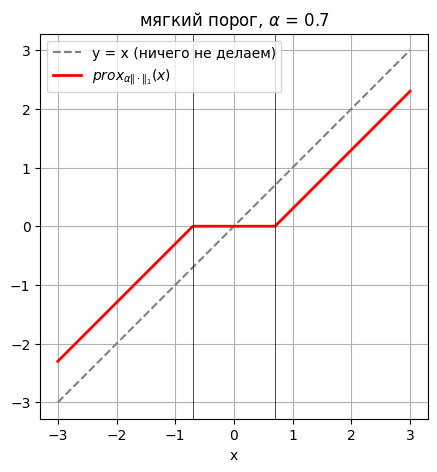

In [7]:
def soft_threshold(x, a):
    """prox_{a * ||.||_1}(x): покомпонентный мягкий порог."""
    return np.sign(x) * np.maximum(np.abs(x) - a, 0.0)

alpha = 0.7
x = np.linspace(-3, 3, 1000)
plt.figure(figsize=(5, 5))
plt.plot(x, x, "--", color="gray", label="y = x (ничего не делаем)")
plt.plot(x, soft_threshold(x, alpha), "r", lw=2, label=r"$prox_{\alpha\|\cdot\|_1}(x)$")
plt.axvline(-alpha, color="k", lw=0.5); plt.axvline(alpha, color="k", lw=0.5)
plt.xlabel("x"); plt.title(rf"мягкий порог, $\alpha$ = {alpha}"); plt.legend(); plt.axis("equal"); plt.show()

Видно: внутри «коридора» всё схлопывается в **ровно ноль**, снаружи — график параллелен $y = x$, но смещён на $\alpha$. Именно поэтому LASSO даёт точные нули.

Тогда шаг $ISTA$ (*Iterative Shrinkage-Thresholding Algorithm*) будет иметь следующий вид (градиент $\nabla f(w) = 2X^T(Xw - y)$, шаг $\alpha_k$ выбираем $=1/L$, $L = 2\lambda_{max}(X^TX)$):

$$w_{k+1} = prox_{\lambda \alpha_k \| \cdot \|_1} (w_k - \alpha_k \nabla f(w_k)) = \text{soft}\Big(w_k - 2\alpha_k X^T(Xw_k - y),\ \lambda \alpha_k\Big)$$

Существует также ускоренная версия ISTA — [**FISTA**](https://www.ceremade.dauphine.fr/~carlier/FISTA) (Fast ISTA): тот же шаг, но применяется не в точке $w_k$, а в точке, «экстраполированной» с учётом импульса (как momentum в градиентном спуске):

$$w_{k+1} = \text{soft}\Big(z_k - \alpha \nabla f(z_k),\ \lambda\alpha\Big), \quad t_{k+1} = \frac{1 + \sqrt{1 + 4t_k^2}}{2}, \quad z_{k+1} = w_{k+1} + \frac{t_k - 1}{t_{k+1}}(w_{k+1} - w_k)$$

Реализуем всё это и сравним с субградиентным спуском и с `sklearn.Lasso`. Данные: 120 объектов, 100 датчиков, из которых на самом деле нужны только 5 (остальные — шум).

In [8]:
rng = np.random.default_rng(0)
m, n = 120, 100
X = rng.standard_normal((m, n))
w_true = np.zeros(n); w_true[:5] = [3, -2, 1.5, 1, -1]      # реально влияют только 5 датчиков
y = X @ w_true + 0.5 * rng.standard_normal(m)
lam = 40.0

def F(w):                                  # целевая функция LASSO
    return np.sum((X @ w - y) ** 2) + lam * np.sum(np.abs(w))

L = 2 * np.linalg.eigvalsh(X.T @ X)[-1]    # константа гладкости f

def ista(n_iter):
    w, hist = np.zeros(n), []
    for _ in range(n_iter):
        w = soft_threshold(w - 2 * X.T @ (X @ w - y) / L, lam / L)
        hist.append(F(w))
    return w, np.array(hist)

def fista(n_iter):
    w, z, t, hist = np.zeros(n), np.zeros(n), 1.0, []
    for _ in range(n_iter):
        w_new = soft_threshold(z - 2 * X.T @ (X @ z - y) / L, lam / L)
        t_new = (1 + np.sqrt(1 + 4 * t ** 2)) / 2
        z = w_new + (t - 1) / t_new * (w_new - w)
        w, t = w_new, t_new
        hist.append(F(w))
    return w, np.array(hist)

def subgradient(n_iter):
    w, hist = np.zeros(n), []
    for k in range(1, n_iter + 1):
        g = 2 * X.T @ (X @ w - y) + lam * np.sign(w)      # один из субградиентов
        w = w - g / (L * np.sqrt(k))                       # шаг ~ 1/sqrt(k)
        hist.append(F(w))
    return w, np.array(hist)

K = 300
w_ista, h_ista = ista(K)
w_fista, h_fista = fista(K)
w_sub, h_sub = subgradient(K)

# эталон: sklearn (там функция делится на 2m, поэтому alpha = lam / (2m))
lasso = Lasso(alpha=lam / (2 * m), fit_intercept=False, tol=1e-12, max_iter=100_000).fit(X, y)
F_star = F(lasso.coef_)

pd.DataFrame({
    "ненулевых весов": [np.count_nonzero(w) for w in (w_ista, w_fista, w_sub, lasso.coef_)],
    "||w - w_sklearn||": [np.linalg.norm(w - lasso.coef_) for w in (w_ista, w_fista, w_sub, lasso.coef_)],
}, index=["ISTA", "FISTA", "субградиентный", "sklearn.Lasso"]).style.format({"||w - w_sklearn||": "{:.1e}"})

,ненулевых весов,||w - w_sklearn||
ISTA,6,3.4e-13
FISTA,6,3.4e-13
субградиентный,100,2.1e-02
sklearn.Lasso,6,0.0e+00


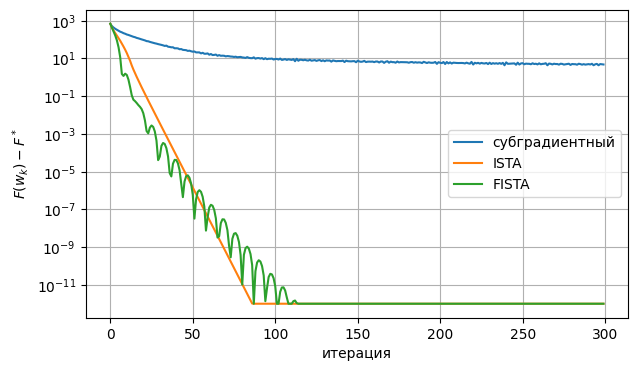

In [9]:
plt.figure(figsize=(7, 4))
for h, name in ((h_sub, "субградиентный"), (h_ista, "ISTA"), (h_fista, "FISTA")):
    plt.semilogy(np.maximum(h - F_star, 1e-12), label=name)
plt.xlabel("итерация"); plt.ylabel(r"$F(w_k) - F^*$"); plt.legend(); plt.show()

Что мы видим:

- ISTA и FISTA нашли то же решение, что и `sklearn.Lasso` (разница порядка $10^{-13}$). Из 100 весов ненулевых всего **6**: 5 «настоящих» датчиков и один шумовой с крошечным весом (≈0.02) — типичная «примесь», которую LASSO при данном $\lambda$ ещё не выкинул. Субградиентный метод «приблизился» к решению, но все 100 весов у него ненулевые: он умеет лишь колебаться вокруг нуля, а не попадать в него.
- По скорости: субградиентный метод топчется на месте (после 300 итераций ошибка всё ещё порядка единиц), ISTA и FISTA выходят на машинную точность за ~100 итераций. FISTA быстрее в самом начале, но «колеблется» (значение функции не убывает монотонно), и на этой задаче ISTA в итоге её догоняет: когда носитель (набор ненулевых весов) определился, задача становится сильно выпуклой, а в этом случае ISTA сходится линейно. Гарантия FISTA — это улучшение в *худшем случае*: $O(1/k^2)$ против $O(1/k)$.

### Регуляризация, как способ отбора признаков.

Вернёмся к станкам. На каждом станке стоят 6 датчиков, износ подшипника мы хотим предсказать:

- **полезные:** вибрация (`vib_rms`), температура подшипника (`temp_bearing`), нагрузка (`load`);
- **шумовые:** влажность в цехе (`humidity`), давление воздуха (`pressure`), номер смены (`shift_noise`) — на износ не влияют вообще.

Истинная зависимость: $\text{износ} = 3\cdot\text{vib} + 2\cdot\text{temp} + 1\cdot\text{load} + \text{шум}$.

Построим **пути регуляризации** — как меняются веса при увеличении $\alpha$.

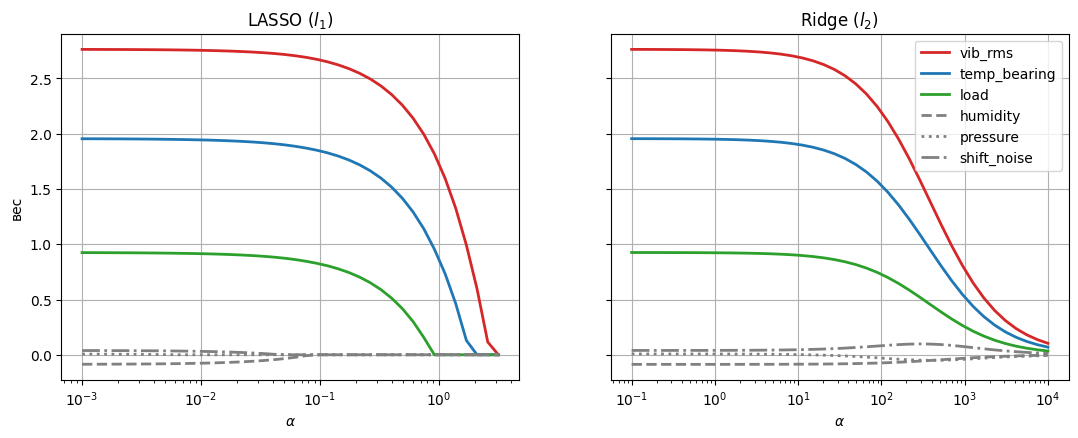

In [6]:
rng = np.random.default_rng(7)
N = 400
a, b, c = rng.standard_normal((3, N))                   # три "настоящих" фактора
noise_sensors = rng.standard_normal((N, 3))

names_1 = ["vib_rms", "temp_bearing", "load", "humidity", "pressure", "shift_noise"]
X1 = np.c_[a, b, c, noise_sensors]
wear = 3 * a + 2 * b + 1 * c + rng.standard_normal(N)

X1_std = StandardScaler().fit_transform(X1)

def coef_path(model_cls, alphas, X, y, **kw):
    return np.array([model_cls(alpha=al, **kw).fit(X, y).coef_ for al in alphas])

def draw_path(ax, alphas, path, names, title, colors, styles):
    for j, name in enumerate(names):
        ax.plot(alphas, path[:, j], color=colors[j], ls=styles[j], lw=2, label=name)
    ax.set_xscale("log"); ax.set_title(title); ax.set_xlabel(r"$\alpha$")

colors1 = ["tab:red", "tab:blue", "tab:green", "gray", "gray", "gray"]
styles1 = ["-", "-", "-", "--", ":", "-."]

alphas_l1 = np.logspace(-3, 0.5, 40)
alphas_l2 = np.logspace(-1, 4, 40)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
draw_path(ax1, alphas_l1, coef_path(Lasso, alphas_l1, X1_std, wear), names_1, "LASSO ($l_1$)", colors1, styles1)
draw_path(ax2, alphas_l2, coef_path(Ridge, alphas_l2, X1_std, wear), names_1, "Ridge ($l_2$)", colors1, styles1)
ax1.set_ylabel("вес"); ax2.legend(loc="upper right"); plt.show()

Основное различие LASSO и Ridge регрессий заключается в том, что первая может приводить к обращению некоторых независимых переменных **в ноль**, тогда как вторая уменьшает их до значений, близких к нулю.

- **LASSO**: шумовые датчики (серые линии) зануляются уже при небольшом $\alpha$ (порядка $0.1$) и остаются на нуле, а полезные доживают до больших $\alpha$ (причём чем слабее датчик — `load` — тем раньше он исчезает, самым последним уходит `vib_rms`).
- **Ridge**: все веса плавно «съезжают» к нулю одновременно. Шумовые тоже малы, но *никогда не равны нулю точно*.

А что будет, если датчики дублируют друг друга? На настоящем станке температура корпуса и температура подшипника почти одно и то же, а `vib_rms` и пиковая вибрация `vib_peak` измеряют фактически одно явление. Добавим по дублю для вибрации и температуры (корреляция ≈ 0.997):

corr(vib_rms, vib_peak) = 0.997


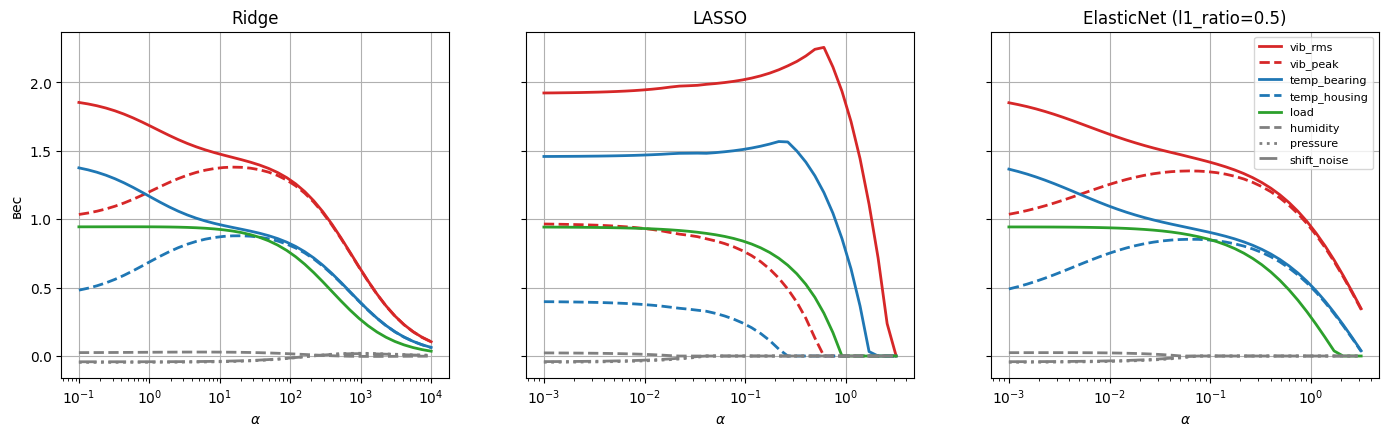

In [7]:
rng = np.random.default_rng(7)
N = 400
a, b, c = rng.standard_normal((3, N))
eps = 0.05

names_2 = ["vib_rms", "vib_peak", "temp_bearing", "temp_housing", "load", "humidity", "pressure", "shift_noise"]
X2 = np.c_[a + eps * rng.standard_normal(N), a + eps * rng.standard_normal(N),      # два датчика вибрации
           b + eps * rng.standard_normal(N), b + eps * rng.standard_normal(N),      # два датчика температуры
           c, rng.standard_normal((N, 3))]
wear2 = 3 * a + 2 * b + 1 * c + rng.standard_normal(N)
X2_std = StandardScaler().fit_transform(X2)
print("corr(vib_rms, vib_peak) =", np.corrcoef(X2[:, 0], X2[:, 1])[0, 1].round(3))

colors2 = ["tab:red", "tab:red", "tab:blue", "tab:blue", "tab:green", "gray", "gray", "gray"]
styles2 = ["-", "--", "-", "--", "-", "--", ":", "-."]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
draw_path(axes[0], alphas_l2, coef_path(Ridge, alphas_l2, X2_std, wear2), names_2, "Ridge", colors2, styles2)
draw_path(axes[1], alphas_l1, coef_path(Lasso, alphas_l1, X2_std, wear2), names_2, "LASSO", colors2, styles2)
draw_path(axes[2], alphas_l1, coef_path(ElasticNet, alphas_l1, X2_std, wear2, l1_ratio=0.5), names_2, "ElasticNet (l1_ratio=0.5)", colors2, styles2)
axes[0].set_ylabel("вес"); axes[2].legend(loc="upper right", fontsize=8); plt.show()

- **Ridge** тянет веса копий друг к другу: при $\alpha$ порядка $10^2$ и выше красные сплошная и пунктирная линии сливаются (так же синие и т.д.). Такое равенство естественно: если два признака одинаковы, то $w_1 x + w_2 x = (w_1 + w_2) x$, а штраф $w_1^2 + w_2^2$ при фиксированной сумме минимален при $w_1 = w_2$. При совсем малых $\alpha$ веса копий различаются — их определяют случайные шумовые различия в данных.
- **LASSO** при росте $\alpha$ по очереди зануляет «лишние» копии: сначала `temp_housing` (при $\alpha \approx 0.25$), затем `vib_peak`. Какую именно копию он оставит — во многом вопрос случая: чуть другая выборка, и «победитель» может смениться. Поэтому, если признаки сильно коррелированы, интерпретировать «какой датчик выбрал LASSO» опасно.
- **ElasticNet** — золотая середина: при достаточно большом $\alpha$ зануляет шумовые датчики, как LASSO, а веса копий держит рядом, как Ridge.

#### Геометрия: почему LASSO даёт нули, а Ridge — нет

Для простоты возьмём два признака. Ограничение на веса в LASSO — это ромб $|w_1| + |w_2| \le t$, в Ridge — круг $w_1^2 + w_2^2 \le t^2$ (задачи с штрафом и с ограничением эквивалентны). Эллипсы — линии уровня ошибки $\|Xw - y\|^2$, центр — решение МНК. Решение с ограничением — первая точка, в которой растущий эллипс **касается** фигуры.

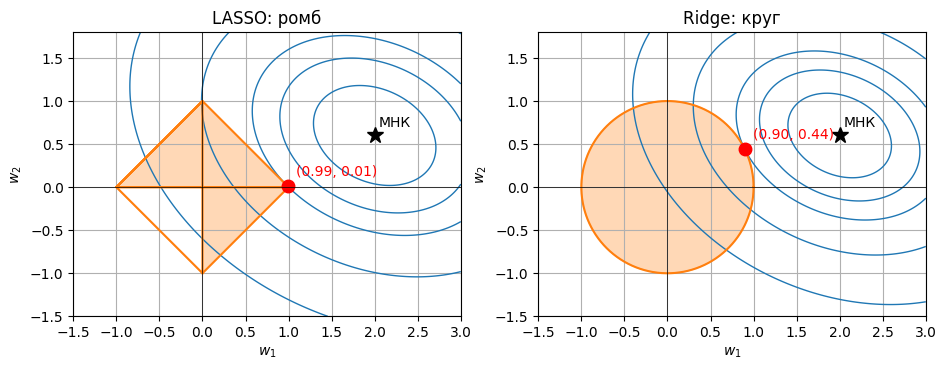

In [8]:
A = np.array([[1.0, 0.3], [0.3, 1.5]])        
w_ols = np.array([2.0, 0.6])                  
t = 1.0

def loss(W):
    d = W - w_ols
    return d[..., 0] ** 2 * A[0, 0] + 2 * d[..., 0] * d[..., 1] * A[0, 1] + d[..., 1] ** 2 * A[1, 1]

s = np.linspace(-1, 1, 4001)
diamond = np.concatenate([np.c_[s, t * (1 - np.abs(s))], np.c_[s, -t * (1 - np.abs(s))],
                          [[t, 0], [-t, 0], [0, t], [0, -t]]])
theta = np.linspace(0, 2 * np.pi, 8000)
circle = t * np.c_[np.cos(theta), np.sin(theta)]

g1, g2 = np.meshgrid(np.linspace(-1.5, 3, 400), np.linspace(-1.5, 1.8, 400))
G = np.stack([g1, g2], axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, boundary, title in ((axes[0], diamond, "LASSO: ромб"), (axes[1], circle, "Ridge: круг")):
    touch = boundary[np.argmin(loss(boundary))]                  # точка границы с минимальной ошибкой
    ax.contour(g1, g2, loss(G), levels=[loss(touch) * k for k in (0.25, 0.6, 1, 2, 4)], colors="tab:blue", linewidths=1)
    ax.fill(*boundary.T, color="tab:orange", alpha=0.3)
    ax.plot(*boundary.T, color="tab:orange")
    ax.plot(*w_ols, "k*", ms=12); ax.annotate("МНК", w_ols + [0.05, 0.1])
    ax.plot(*touch, "ro", ms=9); ax.annotate(f"({touch[0]:.2f}, {touch[1]:.2f})", touch + [0.1, 0.12], color="r")
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_aspect("equal"); ax.set_title(title); ax.set_xlabel("$w_1$"); ax.set_ylabel("$w_2$")
plt.show()

У ромба есть **углы на осях**, и растущий эллипс очень часто натыкается именно на угол — там $w_2 = 0$ (на картинке слева). Круг гладкий, у него нет «выделенных» точек на осях, и точка касания почти никогда не окажется точно на оси (справа). В пространстве большой размерности у «ромба» ещё больше углов и рёбер, поэтому нулей становится много.

#### Масштаб признаков имеет значение

Штраф $\lambda\|w\|$ складывает веса «как есть», но вес зависит от единиц измерения признака. Если измерять вибрацию не в мм/с, а в м/с, то признак станет в 1000 раз меньше, а нужный для него вес — в 1000 раз больше, и штраф за него станет огромным. Проверим:

In [9]:
X1_si = X1.copy()
X1_si[:, 0] *= 0.001                       # vib_rms теперь в "других единицах" (в 1000 раз меньше)

rows = {}
rows["LASSO без стандартизации"] = Lasso(alpha=0.1).fit(X1_si, wear).coef_
rows["LASSO со стандартизацией"] = make_pipeline(StandardScaler(), Lasso(alpha=0.1)).fit(X1_si, wear)[-1].coef_
rows["Ridge без стандартизации (alpha=100)"] = Ridge(alpha=100).fit(X1_si, wear).coef_
rows["Ridge со стандартизацией (alpha=100)"] = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(X1_si, wear)[-1].coef_
pd.DataFrame(rows, index=names_1).T

,vib_rms,temp_bearing,load,humidity,pressure,shift_noise
LASSO без стандартизации,0.000,1.774,0.867,-0.107,0.000,0.153
LASSO со стандартизацией,2.667,1.844,0.821,-0.000,-0.000,0.000
Ridge без стандартизации (alpha=100),0.010,1.479,0.757,-0.154,-0.012,0.211
Ridge со стандартизацией (alpha=100),2.195,1.533,0.728,-0.074,-0.030,0.082


Без стандартизации самый важный датчик `vib_rms` получает вес, близкий к нулю — просто потому, что для него неудобные единицы. Поэтому правило: **перед Ridge / LASSO / ElasticNet признаки стандартизуют** (и делают это внутри `Pipeline`, чтобы в кросс-валидации среднее и дисперсия считались только по обучающей части).

### ElasticNet = Ridge + LASSO

Еще один вид регуляризации, который объединяет в себе, как $L_1$, так и $L_2$ нормы.

$$L_e(w) = \| Xw - y \|_2^2 + \lambda_1 \| w \|_1 + \lambda_2 \| w \|_2^2 \rightarrow \min$$

На картинке выше ElasticNet занимает «середину»: зануляет шум, как LASSO, и делит вес между копиями, как Ridge.

<details>
<summary><b>Для любопытных: вероятностный взгляд</b></summary>

Штраф можно понимать как априорное мнение о весах (байесовская интерпретация):
- Ridge ↔ веса независимы и приходят из нормального распределения с центром в нуле («все веса малы, но не нули»);
- LASSO ↔ веса приходят из распределения Лапласа с центром в нуле — у него острый пик в нуле и тяжёлые хвосты («много нулей и несколько больших весов»).

Решение регуляризованной задачи — это наиболее вероятные веса при этих предположениях (оценка MAP).
</details>

**Промежуточные итоги:**
  - Ridge
    - применяется в случае мультиколлинеарности через добавление $L_2$-регуляризации к функции потерь во время обучения. Для коррелированных признаков **делит вес между ними** (сильные веса уменьшает, но не обнуляет): значения будут приближаться к нулю, но никогда его не достигнут.
    - лучше всего применять гребневую регрессию после стандартизации признаков.
  - LASSO
    - используется для отбора признаков через добавление $L_1$-регуляризации к функции потерь во время обучения. Проще говоря, лассо-регрессия стремится уменьшить число параметров модели путем зануления весов для неинформативных и избыточных признаков, что на выходе даст разреженную модель (с небольшим числом ненулевых весов признаков).
    - на сильно коррелированных признаках выбор «победителя» неустойчив.
  - ElasticNet
    - представляет собой комбинацию $L_1$ и $L_2$-регуляризаций, что может принести особую пользу в ситуациях, когда в данных необходимо одновременно выполнять отбор признаков и бороться с мультиколлинеарностью.

## Регуляризация в Scikit-Learn. Подбор параметра регуляризации

В Scikit-Learn есть реализации всех рассмотренных версий линейной регрессии (и даже больше):
 - [Линейная регрессия без регуляризации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
   - $\|y - Xw\|^2_2$
 - [Ridge регрессия](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
  - $\|y - Xw\|^2_2 + \alpha \cdot \|w\|^2_2$
 - [LASSO регрессия](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html#sklearn.linear_model.Lasso)
  - $\frac{1}{2m} \|y - Xw\|^2_2 + \alpha  \|w\|_1$
 - [ElasticNet регрессия](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html#sklearn.linear_model.ElasticNet)
  - $\frac{1}{2m} \|y - Xw\|^2_2 + \alpha \cdot l_{1_{ratio}} \cdot \|w\|_1 + \frac{\alpha}{2} \cdot (1 - l_{1_{ratio}}) \cdot \|w\|^2_2$

**Осторожно с нормировкой!** У Ridge в sklearn $\alpha = \lambda$ из наших формул, а у LASSO функция поделена на $2m$, поэтому $\alpha_{sklearn} = \lambda / (2m)$ (именно так мы сравнивали с ISTA выше).

Для Ridge, LASSO и ElasticNet есть также реализации, ищущие оптимальное значение параметров регуляризации из заданного множества **по кросс-валидации**:
  - [RidgeCV](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html)
  - [LassoCV](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html)
  - [ElasticNetCV](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNetCV.html)

Применим их к данным про датчики с дублями. Стандартизацию кладём в `Pipeline`.

In [10]:
ols     = make_pipeline(StandardScaler(), LinearRegression()).fit(X2, wear2)
ridge   = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))).fit(X2, wear2)
lasso_cv = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0)).fit(X2, wear2)
enet    = make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=5, random_state=0)).fit(X2, wear2)

print(f"RidgeCV:       alpha = {ridge[-1].alpha_:.3g}")
print(f"LassoCV:       alpha = {lasso_cv[-1].alpha_:.3g}")
print(f"ElasticNetCV:  alpha = {enet[-1].alpha_:.3g}, l1_ratio = {enet[-1].l1_ratio_}")

pd.DataFrame({"МНК": ols[-1].coef_, "RidgeCV": ridge[-1].coef_,
              "LassoCV": lasso_cv[-1].coef_, "ElasticNetCV": enet[-1].coef_}, index=names_2)

RidgeCV:       alpha = 5.88
LassoCV:       alpha = 0.0301
ElasticNetCV:  alpha = 0.0335, l1_ratio = 0.9


,МНК,RidgeCV,LassoCV,ElasticNetCV
vib_rms,1.888,1.511,1.977,1.686
vib_peak,1.000,1.355,0.878,1.163
temp_bearing,1.423,0.991,1.482,1.146
temp_housing,0.434,0.851,0.339,0.672
load,0.944,0.935,0.909,0.909
humidity,0.024,0.029,0.000,0.000
pressure,-0.047,-0.044,-0.013,-0.012
shift_noise,-0.042,-0.040,-0.007,-0.007


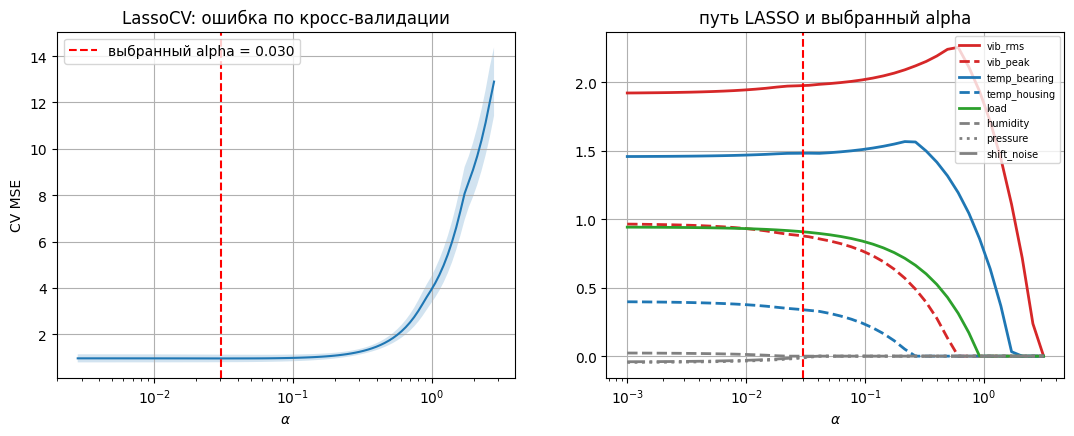

In [11]:
lcv = lasso_cv[-1]
mean_mse, std_mse = lcv.mse_path_.mean(axis=1), lcv.mse_path_.std(axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.semilogx(lcv.alphas_, mean_mse); ax1.fill_between(lcv.alphas_, mean_mse - std_mse, mean_mse + std_mse, alpha=0.2)
ax1.axvline(lcv.alpha_, color="r", ls="--", label=f"выбранный alpha = {lcv.alpha_:.3f}")
ax1.set_xlabel(r"$\alpha$"); ax1.set_ylabel("CV MSE"); ax1.set_title("LassoCV: ошибка по кросс-валидации"); ax1.legend()

alphas_path = np.logspace(-3, 0.5, 40)
draw_path(ax2, alphas_path, coef_path(Lasso, alphas_path, X2_std, wear2), names_2, "путь LASSO и выбранный alpha", colors2, styles2)
ax2.axvline(lcv.alpha_, color="r", ls="--"); ax2.legend(fontsize=7, loc="upper right")
plt.show()

На левом графике — знакомая U-образная кривая: слева переобучение, справа недообучение, и кросс-валидация выбрала $\alpha$ у дна. На правом — тот же $\alpha$ на пути коэффициентов: шумовые датчики практически выключены (`humidity` ровно ноль, у `pressure` и `shift_noise` веса около $0.01$ против $\sim 1$ у полезных), полезные сохранены — причём из дублей LASSO оставил оба датчика вибрации и оба датчика температуры, только с разными весами (см. таблицу выше).

*Замечание.* Метод CV выбирает $\alpha$ по **предсказательному качеству**, поэтому он обычно оставляет чуть больше признаков, чем «истинно нужно» (шум с малыми весами легко проскакивает). Если важен именно отбор признаков, используют более сильный $\alpha$ (например, «правило одного стандартного отклонения»).

## Метрики качества

Мы уже научились ставить задачи машинного обучения, а также познакомились с некоторыми алгоритмами, которые позволяют строить модели, аппроксимирующие зависимости между признаковым описанием и целевой переменной, но как понять насколько качественно мы это делаем? Как понять, какая модель лучше справляется с той или иной задачей?

Если вы участвовали в соревнованиях по машинному обучению (см. [kaggle](https://www.kaggle.com/)), то в них метрика качества определяется за вас организаторами соревнований, в реальной жизни вам самим предстоит разбираться с тем, что такое лучшая модель.

Так, одна из задач дата-саентиста — подобрать критерий, который поможет выбрать лучшую модель.

На лекциях вы уже познакомились с понятием функции ошибки и эмпирического риска.

__Loss function__ ($L(a,x): \mathbb{X} \rightarrow \mathbb{R}$) — отображение, показывающее «стоимость» ошибки.

__Эмпирический риск__ — средняя величина ошибки на обучающей выборке.
$$Q(a, X^m) = \frac{1}{m} \sum_{x \in X^m} L(a, x)$$

__Важно помнить, что функция потерь/эмпирический риск $\neq$ метрика качества.__

- _Метрика качества_ — внешний критерий, который не зависит от параметров модели, а отображает качество решения исходной задачи (предсказанных меток).
- _Функция потерь_ появляется в момент, когда задача построения модели сводится к задаче оптимизации для получения наилучших параметров. Зачастую эта функция должна обладать некоторыми свойствами, например, дифференцируемостью.

Однако в некоторых случаях метрика качества может совпадать с функцией потерь. Так в задаче регрессии [$MSE$](https://en.wikipedia.org/wiki/Mean_squared_error) может выступать как в роли метрики качества, так и в роли функции потерь.

**Почему они часто разные?** Допустим, мы хотим максимизировать accuracy, то есть минимизировать долю ошибок $\mathbb{I}[a(x) \ne y]$ («0-1 loss»). Но эта функция кусочно-постоянна — градиент почти везде нулевой, обучать по ней нечем. Поэтому в оптимизации заменяют её гладкой «верхней оценкой» (логистическая потеря, hinge и т.д.), а оценивают модель всё равно по accuracy / F1 / AUC.

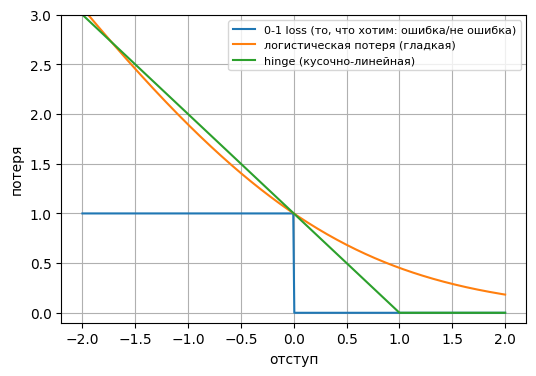

In [12]:
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score, f1_score,
                             fbeta_score, roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, log_loss, classification_report,
                             mean_squared_error, mean_absolute_error, r2_score)
from scipy.stats import norm

# отступ M = y * f(x): M > 0 — объект классифицирован верно, M < 0 — ошибка
M_ = np.linspace(-2, 2, 400)
plt.figure(figsize=(6, 4))
plt.plot(M_, (M_ < 0).astype(float), label="0-1 loss (то, что хотим: ошибка/не ошибка)")
plt.plot(M_, np.log2(1 + np.exp(-M_)), label="логистическая потеря (гладкая)")
plt.plot(M_, np.maximum(0, 1 - M_), label="hinge (кусочно-линейная)")
plt.ylim(-0.1, 3); plt.xlabel("отступ"); plt.ylabel("потеря"); plt.legend(fontsize=8); plt.show()

### Задача бинарной классификации: I

**Сюжет.** На производство поступило $110$ станков: $100$ исправны и $10$ неисправны. Наш алгоритм по показаниям датчиков выдаёт для каждого станка оценку «степени неисправности» от 0 до 1 (чем больше — тем больше уверенность, что станок неисправен); решение «неисправен», если оценка больше $0.5$. Положительным классом (класс $1$) будем считать **неисправный** станок — ловить нужно именно их.

Сгенерируем такие данные (для воспроизводимости зафиксирован seed, при котором на пороге $0.5$ получаются в точности те числа, что разбираются ниже).

In [13]:
rng = np.random.default_rng(85)
score_healthy = rng.beta(2, 5, 100)       # у исправных станков оценка обычно маленькая
score_faulty  = rng.beta(4, 3, 10)        # у неисправных — в среднем побольше, но перекрытие есть

score  = np.r_[score_healthy, score_faulty]
y_true = np.r_[np.zeros(100, dtype=int), np.ones(10, dtype=int)]
y_pred = (score > 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
print(f"TP = {tp}, FP = {fp}, FN = {fn}, TN = {tn}")
assert (tp, fp, fn, tn) == (5, 10, 5, 90)

TP = 5, FP = 10, FN = 5, TN = 90


#### [Accuracy](https://scikit-learn.org/dev/modules/generated/sklearn.metrics.accuracy_score.html)
- доля корректно предсказанных примеров
$$accuracy(y, \hat{y}) = \frac{1}{m} \sum_{i=1}^m \mathbb{I}[a(x_i) = y_i]$$
- сопряженная ей метрика — доля ошибочных классификаций (__error rate__)
$$ErrorRate = 1 - accuracy$$

Accuracy имеет $2$ существенных недостатка:
 - не учитывает дисбаланс классов
 - не учитывает цену ошибки для объектов разных классов

Посмотрим на первый.
Из $100$ исправных станков $90$ наш классификатор определил верно, а среди $10$ неисправных верно определено $5$. Таким образом,
$$accuracy = \frac{1}{110} (90 + 5) = \frac{95}{110} = 0.86$$

Теперь возьмём «глупый» классификатор, который про каждый станок говорит: «Исправен» (никаких датчиков не смотрит):
$$accuracy = \frac{100}{110} = 0.91$$

In [14]:
y_const = np.zeros(110, dtype=int)         # "всегда исправен"
print(f"наш классификатор:  accuracy = {accuracy_score(y_true, y_pred):.3f}")
print(f"всегда 'исправен':  accuracy = {accuracy_score(y_true, y_const):.3f}")

наш классификатор:  accuracy = 0.864
всегда 'исправен':  accuracy = 0.909


**Глупый классификатор «победил»**, хотя не нашёл ни одного неисправного станка — а ловить их и было целью. Дело в том, что 91% станков исправны, и «всегда исправен» уже даёт 91%.

Второй недостаток — разная цена ошибки: пропустить неисправный станок (он сломается в цеху) обычно гораздо дороже, чем отправить исправный на лишнюю проверку. Accuracy считает эти ошибки одинаковыми.

Чтобы различать типы ошибок, перейдём к матрице ошибок.

#### [Confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)

Чтобы познакомиться с матрицей ошибок, разберемся какие предсказания может давать классификатор в бинарном случае:
- верно предсказываем положительную метку. Такие объекты обозначаются, как **true positive (TP)**. True — потому что предсказали мы правильно, а positive — потому что предсказали положительную метку
- предсказываем положительную метку, но ошибаемся в своём предсказании — **false positive (FP)**. False, потому что предсказание было неправильным
- предсказываем отрицательную метку, но ошибаемся — **false negative (FN)**
- верно предсказываем отрицательную метку — **true negative (TN)**

Для удобства все эти 4 числа изображают в виде таблицы, которую называют **confusion matrix**. Мы будем писать истинные классы по строкам, а предсказанные по столбцам (так же, как в sklearn; в других учебниках иногда меняют местами — всегда смотрите на подписи!):

| <!---  ---> | $\hat{y} = 1$ | $\hat{y} = 0$ |
|--------------|--------------|--------------|
| $y = 1$ | True Positive (TP)   | False Negative (FN) |
| $y = 0$ | False Positive (FP)   | True Negative (TN) |

В sklearn `confusion_matrix(y_true, y_pred)` возвращает `[[TN, FP], [FN, TP]]` (строки и столбцы упорядочены по возрастанию метки: сначала класс 0, потом 1).

Таким образом, мы можем совершить $2$ типа ошибок: $FP$ и $FN$. Они также называются ошибками I и II рода (FP — I рода, «ложная тревога», FN — II рода, «пропуск цели»).

<div style="text-align:center">
<img src="src/error_type.jpeg" width="650px">
</div>

In [15]:
cm = confusion_matrix(y_true, y_pred)
pd.DataFrame(cm, index=["истина: исправен (0)", "истина: неисправен (1)"],
                 columns=["предсказано: исправен (0)", "предсказано: неисправен (1)"])

,предсказано: исправен (0),предсказано: неисправен (1)
истина: исправен (0),90,10
истина: неисправен (1),5,5


Матрица ошибок не является каким-то показателем качества, хотя мы и стремимся максимизировать главную диагональ и минимизировать недиагональные элементы (однако на матрицах не задан порядок, а потому сравнить $2$ произвольные матрицы мы не можем), она дает нам инструмент для анализа ошибок.

Также с помощью введенных обозначений мы можем переписать формулы для $accuracy$ и $error\_rate$:
$$accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$
$$ErrorRate = \frac{FP + FN}{TP + TN + FP + FN}$$

Что показывает нам, что $accuracy$ оперирует только верными предсказаниями, а $ErrorRate$ неверными. При этом, как мы уже посмотрели в случае дисбаланса классов $accuracy$ может быть обманчивой, это же касается и $ErrorRate$.

__Accuracy__ имеет смысл применять, когда отсутствует сильный дисбаланс классов и классы имеют одинаковое значение.

Зачастую класс, который представляет для нас интерес, обозначается «положительным», верные предсказания на нем $TP$, поэтому в случае асимметрии классов можно использовать метрики, которые ориентируются на $TP$ и не используют $TN$.

#### [Precision (точность)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html)

- Доля правильно предсказанных положительных объектов среди всех объектов, предсказанных положительными.

$$Precision = \frac{TP}{TP + FP}$$

- Чем меньше ложноположительных срабатываний будет допускать алгоритм, тем больше будет значение $Precision$.

#### [Recall (полнота)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html)

- Доля правильно предсказанных положительных объектов среди всех объектов, являющихся положительными.

$$Recall = \frac{TP}{TP + FN}$$

- Чем меньше ложноотрицательных срабатываний будет допускать алгоритм, тем больше будет значение $Recall$.

<div style="text-align:center">
<img src="src/prec_rec.png" width="250px">
</div>

На станках: precision — «из станков, которые мы остановили на ремонт, сколько действительно были неисправны», recall — «какую долю неисправных станков мы вообще нашли». В задаче предсказания злокачественности опухоли аналогично: точность показывает, сколько из определённых нами как злокачественные опухолей действительно злокачественные, а полнота — какую долю злокачественных опухолей нам удалось выявить.

__Precision__ и __Recall__ не используют $TN$, поэтому не раздуваются от огромного числа «лёгких» отрицательных объектов (как это происходило с accuracy). Но не путайте это с независимостью от баланса: **precision зависит от доли положительных** — при тех же TPR и FPR, если отрицательных станков в 100 раз больше, ложных срабатываний становится в 100 раз больше, и precision падает (пример ниже, в разделе про статьи). Recall же зависит только от положительных объектов.

In [16]:
def report(y, pred, name):
    return {"модель": name,
            "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred),
            "F1": f1_score(y, pred, zero_division=0)}

pd.DataFrame([report(y_true, y_pred, "наш классификатор"),
              report(y_true, y_const, "всегда 'исправен'")]).set_index("модель")

,accuracy,precision,recall,F1
модель,,,,
наш классификатор,0.864,0.333,0.500,0.400
всегда 'исправен',0.909,0.000,0.000,0.000


Теперь картина честная: у «всегда исправен» recall = 0 (он не нашёл ни одного неисправного станка) и precision не определён (он вообще ни разу не сказал «неисправен»; sklearn в таком случае возвращает 0). У нашего классификатора recall = 0.5 (нашли половину неисправных), precision = 0.33 (из 15 остановленных станков реально неисправны только 5).

На практике стоит задача найти баланс между парой $Precision-Recall$, одним из популярных способов их комбинации является $F_1$ мера — среднее гармоническое $Precision$ и $Recall$.

#### [$F_1$ - мера](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)

$$F_1 = \frac{2}{\frac{1}{Recall} + \frac{1}{Precision}} = 2 \frac{Recall \cdot Precision}{Recall + Precision}$$

Почему именно гармоническое, а не арифметическое среднее? Потому что оно «не прощает» перекоса. Алгоритм, который называет неисправными вообще все станки подряд, имеет recall $= 1$ и precision близкую к нулю. Арифметическое среднее скажет «примерно 0.5 — нормально!», гармоническое — «плохо».

In [17]:
P, R = 1.0, 0.01          # очень точный, но находит почти ничего
print("арифметическое среднее:", (P + R) / 2)
print("F1 (гармоническое):    ", 2 * P * R / (P + R))

арифметическое среднее: 0.505
F1 (гармоническое):     0.019801980198019802


$F_1$-мера предполагает одинаковый приоритет у $Recall$ и $Precision$. У нее есть обобщение, которое позволяет балансировать между важностью $Recall$ и $Precision$.

#### [$F_{\beta}$ - мера](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.fbeta_score.html)

$$F_{\beta} =  (\beta^2 + 1) \frac{Recall \cdot Precision}{Recall + \beta^2 Precision}$$

При $\beta > 1$ важнее $Recall$, при $\beta < 1$ — $Precision$. На станках пропуск неисправного дороже ложной тревоги, поэтому логично взять $\beta = 2$:

In [18]:
print(f"F1 = {f1_score(y_true, y_pred):.3f}")
print(f"F2 = {fbeta_score(y_true, y_pred, beta=2):.3f}   (recall важнее)")
print(f"F0.5 = {fbeta_score(y_true, y_pred, beta=0.5):.3f}   (precision важнее)")

F1 = 0.400
F2 = 0.455   (recall важнее)
F0.5 = 0.357   (precision важнее)


### Задача бинарной классификации: II

Многие модели МО, решающие задачу бинарной классификации, устроены таким образом, что разделяют объекты по классам на основе некоторого порога:

$$f(x, w, w_0) = \mathbb{I}[g(x, w) > w_0]$$

В частности простейший линейный классификатор будет устроен следующим образом:

$$f(x, w, w_0) = \mathbb{I}[x^Tw > 0]$$

Однако такое преобразование приводит к потере информации, поскольку результат бинарной классификации не показывает, насколько выше или ниже значения порога отсечения. Нужно учитывать, что в зависимости от порога мы будем получать разные предсказания и разное качество на отложенной выборке. Как в этом случае оценивать качество модели?

Посмотрим на наших станках, что делает порог. Выбрали порог $0.3$ — ловим почти всех, но много ложных тревог; порог $0.7$ — почти нет ложных тревог, но много пропусков:

In [19]:
def at_threshold(thr):
    pred = (score > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"порог": thr, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall (TPR)": tp / (tp + fn), "FPR": fp / (fp + tn)}

thr_table = pd.DataFrame([at_threshold(t) for t in (0.3, 0.5, 0.7)]).set_index("порог")
thr_table.style.format({"precision": "{:.2f}", "recall (TPR)": "{:.2f}", "FPR": "{:.2f}"})

,TP,FP,FN,TN,precision,recall (TPR),FPR
порог,,,,,,,
0.300000,9,46,1,54,0.16,0.90,0.46
0.500000,5,10,5,90,0.33,0.50,0.10
0.700000,2,2,8,98,0.50,0.20,0.02


Рассмотрим $2$ величины, которые монотонно не убывают при уменьшении порога:

$$TruePositiveRate = TPR = \frac{TP}{TP + FN} \ \ (\text{совпадает с } Recall)$$

$$FalsePositiveRate = FPR = \frac{FP}{FP + TN}$$

__TruePositiveRate__ ( $TPR$ ) — доля положительных объектов, правильно предсказанных положительными (полнота).

__FalsePositiveRate__ ( $FPR$ ) — доля отрицательных объектов, неправильно предсказанных положительными.

Кривая, построенная в координатах $ \ TPR( \ FPR \ )$ при варьировании порога, называется [__ROC-кривой__](http://www.machinelearning.ru/wiki/index.php?title=ROC-%D0%BA%D1%80%D0%B8%D0%B2%D0%B0%D1%8F). Каждая точка на графике соответствует выбору некоторого порога. Она проходит из точки $(0,0)$, соответствующей максимальному значению $w_0$, в точку $(1,1)$, соответствующую минимальному значению $w_0$.

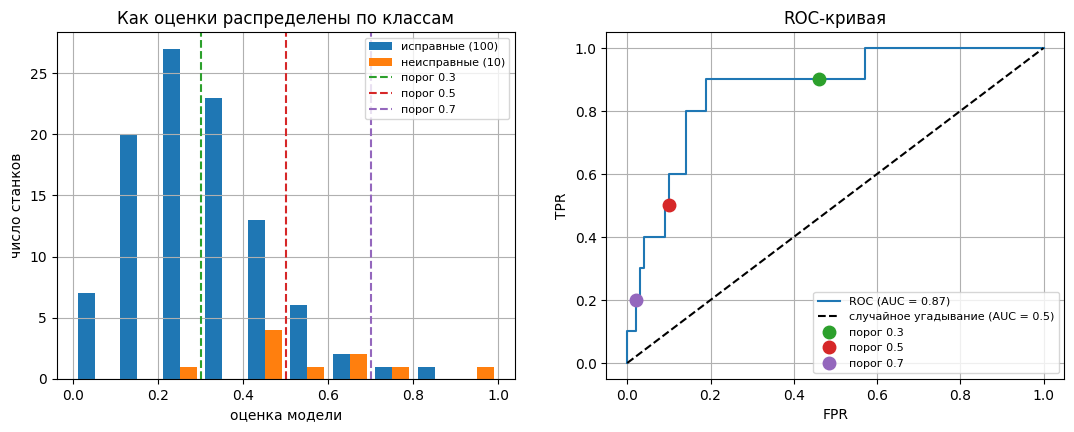

In [20]:
fpr, tpr, _ = roc_curve(y_true, score)
auc = roc_auc_score(y_true, score)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(0, 1, 11)
ax1.hist([score_healthy, score_faulty], bins, label=["исправные (100)", "неисправные (10)"])
for thr, col in zip((0.3, 0.5, 0.7), ("tab:green", "tab:red", "tab:purple")):
    ax1.axvline(thr, color=col, ls="--", label=f"порог {thr}")
ax1.set_xlabel("оценка модели"); ax1.set_ylabel("число станков"); ax1.legend(fontsize=8)
ax1.set_title("Как оценки распределены по классам")

ax2.plot(fpr, tpr, drawstyle="steps-post", label=f"ROC (AUC = {auc:.2f})")
ax2.plot([0, 1], [0, 1], "k--", label="случайное угадывание (AUC = 0.5)")
for thr, col in zip((0.3, 0.5, 0.7), ("tab:green", "tab:red", "tab:purple")):
    r = at_threshold(thr)
    ax2.plot(r["FPR"], r["recall (TPR)"], "o", color=col, ms=9, label=f"порог {thr}")
ax2.set_xlabel("FPR"); ax2.set_ylabel("TPR"); ax2.legend(fontsize=8); ax2.set_title("ROC-кривая")
plt.show()

Двигаем порог влево — движемся по ROC-кривой вправо-вверх: растёт TPR (находим больше неисправных), но растёт и FPR (больше ложных тревог). Идеальный классификатор проходил бы через левый верхний угол $(0, 1)$.

Если хочется поиграть с порогом руками — ячейка со слайдером (нужен `ipywidgets`):

In [21]:
try:
    import ipywidgets as widgets

    def show_threshold(thr=0.5):
        r = at_threshold(thr)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
        ax1.hist([score_healthy, score_faulty], bins, label=["исправные", "неисправные"])
        ax1.axvline(thr, color="r", ls="--"); ax1.legend(); ax1.set_xlabel("оценка модели")
        ax2.plot(fpr, tpr, drawstyle="steps-post"); ax2.plot([0, 1], [0, 1], "k--")
        ax2.plot(r["FPR"], r["recall (TPR)"], "ro", ms=10)
        ax2.set_xlabel("FPR"); ax2.set_ylabel("TPR")
        plt.show()
        print(f"TP={r['TP']}  FP={r['FP']}  FN={r['FN']}  TN={r['TN']}   "
              f"precision={r['precision']:.2f}  recall={r['recall (TPR)']:.2f}  FPR={r['FPR']:.2f}")

    widgets.interact(show_threshold, thr=widgets.FloatSlider(min=0.05, max=0.95, step=0.05, value=0.5))
except ImportError:
    print("ipywidgets не установлен (pip install ipywidgets) — слайдер пропускаем, таблица выше показывает то же самое.")

interactive(children=(FloatSlider(value=0.5, description='thr', max=0.95, min=0.05, step=0.05), Output()), _do…

<div style="text-align:center">
<img src="src/ROC.png" width="650px">
</div>

Чем выше лежит кривая, тем лучше качество классификации. ROC-кривая может быть вычислена по любой выборке. Однако ROC-кривая, вычисленная по обучающей выборке, является оптимистично смещённой влево-вверх вследствие переобучения. Величину этого смещения предсказать довольно трудно, поэтому на практике ROC-кривую всегда оценивают по независимой тестовой выборке.

#### [ROC-AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html)

Площадь под ROC-кривой AUC (Area Under Curve) является агрегированной характеристикой качества классификации, не зависящей от соотношения цен ошибок. Чем больше значение AUC, тем «лучше» модель классификации.

Имея аналитическую зависимость $TPR(x)$, $FPR(x)$ от порога бинаризации $x$ (в предположении, что $x \in [0, 1]$) можно записать площадь под ROC-кривой, как

$$ROC-AUC = \int_1^0 TPR(x) FPR'(x) dx$$

__AUC ROC__ равен доле пар объектов вида (объект класса 1, объект класса 0), которые алгоритм верно упорядочил (если у пары одинаковые оценки, засчитывают половину). Может быть интерпретирован как вероятность того, что случайно выбранный положительный объект будет проранжирован классификатором выше (будет иметь более высокую вероятность быть «положительным»), чем случайно выбранный «отрицательный» объект. Таким образом, в любой задаче, где нам важна не метка сама по себе, а правильный порядок на объектах, имеет смысл применять AUC.

Проверим это определение на совсем маленьком примере: 3 неисправных станка и 3 исправных.

In [22]:
pos = np.array([0.9, 0.6, 0.35])       # оценки неисправных станков
neg = np.array([0.7, 0.4, 0.2])        # оценки исправных станков

pairs = [(p, n) for p in pos for n in neg]
correct = sum(p > n for p, n in pairs)
print(f"верно упорядочено пар: {correct} из {len(pairs)}  ->  доля = {correct / len(pairs):.4f}")
print(f"roc_auc_score          = {roc_auc_score([1, 1, 1, 0, 0, 0], np.r_[pos, neg]):.4f}")

верно упорядочено пар: 6 из 9  ->  доля = 0.6667
roc_auc_score          = 0.6667


Подробнее о ROC-AUC, а также о том, как ее строить, настоятельно советуем ознакомиться в [__материалах А.Г. Дьяконова__](https://alexanderdyakonov.wordpress.com/2017/07/28/auc-roc-%D0%BF%D0%BB%D0%BE%D1%89%D0%B0%D0%B4%D1%8C-%D0%BF%D0%BE%D0%B4-%D0%BA%D1%80%D0%B8%D0%B2%D0%BE%D0%B9-%D0%BE%D1%88%D0%B8%D0%B1%D0%BE%D0%BA/). [Задачи для проверки себя.](https://alexanderdyakonov.wordpress.com/2015/10/09/%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%D0%BA%D0%B8-%D0%BF%D1%80%D0%BE-auc-roc/)

#### Когда ROC-AUC вводит в заблуждение: сюжет про статьи

Рассмотрим задачу выделения математических статей из множества научных статей. Допустим, что всего имеется $1010$ статей, из которых лишь $10$ относятся к математике. Если нам удастся построить алгоритм $a(x)$, идеально решающий задачу, то его $TPR$ будет равен единице, а $FPR$ — нулю.

Рассмотрим теперь «плохой» алгоритм, дающий положительный ответ на $9$ математических и $50$ нематематических статей. Такой алгоритм в реальности малополезен — из 59 статей, которые он считает математическими, только 9 действительно математические, — но при этом имеет $TPR = \frac{9}{10} = 0.9$ и $FPR = \frac{50}{1000} = 0.05$, что внешне очень близко к показателям идеального алгоритма. Таким образом, если положительный класс существенно меньше по размеру, то AUC-ROC может давать неадекватную оценку качества работы алгоритма, поскольку измеряет долю неверно принятых объектов относительно общего числа отрицательных.

In [23]:
TP, FN, FP, TN = 9, 1, 50, 950              # 10 математических и 1000 остальных статей
print(f"TPR = {TP/(TP+FN):.2f}, FPR = {FP/(FP+TN):.2f}   <- выглядит почти идеально")
print(f"precision = {TP/(TP+FP):.2f}, F1 = {2*TP/(2*TP+FP+FN):.2f}   <- а на самом деле только каждая 7-я 'математическая' статья настоящая")
print(f"accuracy = {(TP+TN)/1010:.3f}   (а у 'всё нематематика' — {1000/1010:.3f})")

# тот же классификатор (TPR = 0.9, FPR = 0.05), но если математических статей столько же, сколько остальных:
for pos_count, neg_count in ((100, 100), (10, 1000)):
    tp, fp_ = 0.9 * pos_count, 0.05 * neg_count
    print(f"положительных: {pos_count:>3}, отрицательных: {neg_count:>4}  ->  precision = {tp/(tp+fp_):.2f}")

TPR = 0.90, FPR = 0.05   <- выглядит почти идеально
precision = 0.15, F1 = 0.26   <- а на самом деле только каждая 7-я 'математическая' статья настоящая
accuracy = 0.950   (а у 'всё нематематика' — 0.990)
положительных: 100, отрицательных:  100  ->  precision = 0.95
положительных:  10, отрицательных: 1000  ->  precision = 0.15


Тот же самый классификатор (с теми же TPR и FPR, то есть с той же точкой на ROC-кривой!) имеет precision $0.95$ при сбалансированных классах и $0.15$ при $1:100$. ROC-кривая от баланса классов не зависит (TPR и FPR считаются внутри каждого класса отдельно), а precision зависит. Поэтому при редком положительном классе разумнее смотреть на PR-кривую.

#### Precision-recall (PR) кривая. [AUC-PR](https://scikit-learn.org/dev/modules/generated/sklearn.metrics.average_precision_score.html#sklearn.metrics.average_precision_score)

Избавиться от указанной проблемы с несбалансированными классами можно, перейдя от ROC-кривой к PR-кривой. Она определяется аналогично ROC-кривой, только по осям откладываются не FPR и TPR, а полнота ($recall$) (по оси абсцисс) и точность ($precision$) (по оси ординат). Критерием качества семейства алгоритмов выступает площадь под PR-кривой (Area Under the Curve — AUC-PR).

<div style="text-align:center">
<img src="src/PR.png" width="620px">
</div>

Рассмотрим среднее значение точности (оно равно площади под кривой точность-полнота):

$$AP = \int_0^1 p(r)dr$$

Получим показатель эффективности, который называется average precision.

На станках то же самое: у нас 10 из 110 неисправных, и PR-кривая нашей модели выглядит так:

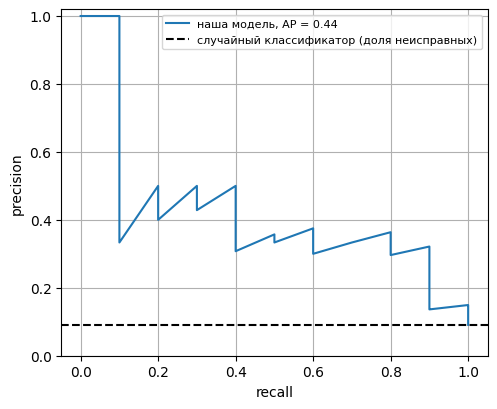

ROC-AUC = 0.87,  AP = 0.44


In [24]:
prec, rec, _ = precision_recall_curve(y_true, score)
plt.figure(figsize=(5.5, 4.5))
plt.plot(rec, prec, label=f"наша модель, AP = {average_precision_score(y_true, score):.2f}")
plt.axhline(10 / 110, color="k", ls="--", label="случайный классификатор (доля неисправных)")
plt.xlabel("recall"); plt.ylabel("precision"); plt.ylim(0, 1.02); plt.legend(fontsize=8); plt.show()
print(f"ROC-AUC = {roc_auc_score(y_true, score):.2f},  AP = {average_precision_score(y_true, score):.2f}")

#### Логарифмическая функция потерь (log-loss)

До сих пор мы оценивали либо метки (accuracy, F1, ...), либо порядок объектов (AUC). Часто нужно оценивать и сами **вероятности**: если модель говорит «станок неисправен с вероятностью 0.99», а он исправен — это хуже, чем «с вероятностью 0.55». Для этого есть [log-loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html) (бинарная кросс-энтропия), которой обычно обучают классификаторы (логистическая регрессия, нейросети):

$$LogLoss = -\frac{1}{m}\sum_{i=1}^m \Big[y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big]$$

Это как раз пример того, что функция потерь (гладкая, по ней можно обучать) бывает полезна и как метрика: она штрафует уверенные ошибки очень сильно.

In [25]:
yy = np.array([1] * 5 + [0] * 5)
p_A = np.array([0.9, 0.9, 0.9, 0.9, 0.01, 0.1, 0.1, 0.1, 0.1, 0.1])    # одну ошибку делает с большой уверенностью
p_B = np.array([0.9, 0.9, 0.9, 0.9, 0.45, 0.1, 0.1, 0.1, 0.1, 0.1])    # ту же ошибку делает «неуверенно»

for name, p in (("модель A (уверенная ошибка)", p_A), ("модель B (осторожная ошибка)", p_B)):
    print(f"{name}: accuracy = {accuracy_score(yy, p > 0.5):.1f}, log-loss = {log_loss(yy, p):.3f}")

модель A (уверенная ошибка): accuracy = 0.9, log-loss = 0.555
модель B (осторожная ошибка): accuracy = 0.9, log-loss = 0.175


У двух моделей **одинаковая accuracy** (они ошиблись на одном и том же объекте), но log-loss различает их: модель A заплатила гораздо больше за самоуверенную ошибку.

### Многоклассовая классификация

Если классов становится больше двух, расчёт метрик усложняется. Если задача классификации на $K$ классов ставится как $K$ задач об отделении класса $i$ от остальных $(i = 1,..., K)$, то для каждой из них можно посчитать свою матрицу ошибок. Затем есть два варианта получения итогового значения метрики из K матриц ошибок:

 - Усредняем элементы матрицы ошибок $(TP, FP, TN, FN)$ между бинарными классификаторами, например $TP=\frac{1}{K}\sum_{i=1}^K TP_i$. Затем по одной усреднённой матрице ошибок считаем $Precision$, $Recall$, $F$-меру. Это называют __микроусреднением__.
 - Считаем $Precision$, $Recall$ для каждого классификатора отдельно, а потом усредняем. Это называют __макроусреднением__.

__Важно__: Порядок усреднения влияет на результат в случае дисбаланса классов. Микро-усреднение «голосует объектами» (большие классы перевешивают), макро — «голосует классами» (каждый класс весит одинаково, в том числе редкий).

**Пример.** Теперь классификатор определяет не только «исправен/неисправен», но и тип неисправности: `исправен` (900 станков), `подшипник` (80), `перегрев` (20, редкая неисправность).

In [26]:
classes = ["исправен", "подшипник", "перегрев"]
cm3 = np.array([[880, 15,  5],         # строки — истина, столбцы — предсказание
                [ 10, 65,  5],
                [  5,  5, 10]])
display(pd.DataFrame(cm3, index=[f"истина: {c}" for c in classes], columns=[f"предсказано: {c}" for c in classes]))

y3_true = np.repeat([0, 1, 2], cm3.sum(axis=1))
y3_pred = np.concatenate([np.repeat([0, 1, 2], row) for row in cm3])

print(classification_report(y3_true, y3_pred, target_names=classes, digits=3))

rows = {avg: {"precision": precision_score(y3_true, y3_pred, average=avg),
              "recall": recall_score(y3_true, y3_pred, average=avg),
              "F1": f1_score(y3_true, y3_pred, average=avg)} for avg in ("micro", "macro")}
display(pd.DataFrame(rows).T)
print(f"accuracy = {accuracy_score(y3_true, y3_pred):.3f}")

,предсказано: исправен,предсказано: подшипник,предсказано: перегрев
истина: исправен,880,15,5
истина: подшипник,10,65,5
истина: перегрев,5,5,10


              precision    recall  f1-score   support

    исправен      0.983     0.978     0.981       900
   подшипник      0.765     0.812     0.788        80
    перегрев      0.500     0.500     0.500        20

    accuracy                          0.955      1000
   macro avg      0.749     0.763     0.756      1000
weighted avg      0.956     0.955     0.955      1000



,precision,recall,F1
micro,0.955,0.955,0.955
macro,0.749,0.763,0.756


accuracy = 0.955


- **Микро**-усреднение даёт 0.955 — и это ровно accuracy (в задаче, где у каждого объекта ровно один класс, micro-precision = micro-recall = micro-F1 = accuracy). Оно почти полностью определяется большим классом «исправен».
- **Макро**-усреднение даёт 0.75: у редкого класса «перегрев» recall всего 0.5, и макро-среднее честно «замечает» это (все три класса весят одинаково).

Выбирайте усреднение по смыслу задачи: важен каждый объект — micro; важен каждый класс (в т.ч. редкий) — macro.

### Регрессия

В задаче регрессии нас зачастую интересует величина невязки: $e_i = a(x_i) - y_i$, которую необходимо агрегировать по набору данных.

#### [(R)MSE](https://scikit-learn.org/1.5/modules/generated/sklearn.metrics.mean_squared_error.html)

Одна из самых популярных метрик, которая также часто используется как функция потерь для многих моделей — это $MSE$.

$$MSE(y, \hat{y}) = \frac{1}{m} \sum_{i=1}^m (y_i - a(x_i))^2 $$

Чтобы показатель эффективности MSE имел размерность исходных данных, иногда из него извлекают квадратный корень и получают показатель эффективности RMSE.

$$RMSE(y, \hat{y}) = \sqrt{\frac{1}{m} \sum_{i=1}^m (y_i - a(x_i))^2 } $$

MSE неограничен сверху, и может быть нелегко понять, насколько «хорошим» или «плохим» является то или иное его значение.

Если большие ошибки для нас действительно неприемлемы, то квадратичный штраф за них — очень полезное свойство (и его даже можно усиливать, повышая степень, в которую мы возводим ошибку на объекте). Однако если в наших тестовых данных присутствуют выбросы, то нам будет сложно объективно сравнить модели между собой: ошибки на выбросах будут маскировать различия в ошибках на основном множестве объектов.

#### [MAE](https://scikit-learn.org/dev/modules/generated/sklearn.metrics.mean_absolute_error.html)

Использовать $RMSE$ для сравнения моделей на выборках с большим количеством выбросов может быть неудобно. В таких случаях прибегают к также знакомой вам в качестве функции потери метрике $MAE$ (mean absolute error):

$$MAE(y, \hat{y}) = \frac{1}{m} \sum_{i=1}^{m} | y_i - a(x_i) |  $$

**Пример.** Износ подшипников у 6 станков (мм), и две модели. Модель A почти идеальна везде, но на одном станке ошибается сильно (выброс). Модель B слегка ошибается на всех.

In [27]:
y_wear = np.array([2.0, 5.0, 3.0, 8.0, 6.0, 4.0])
pred_A = y_wear + np.array([0.2, -0.2, 0.2, -0.2, 0.2, 2.0])    # хороша везде, кроме последнего станка
pred_B = y_wear + np.array([0.6, -0.6, 0.6, -0.6, 0.6, -0.6])   # одинаково «средняя» везде

def reg_report(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R²": r2_score(y, p)}

pd.DataFrame({"модель A (выброс)": reg_report(y_wear, pred_A), "модель B (ровная)": reg_report(y_wear, pred_B)}).T

,MAE,RMSE,R²
модель A (выброс),0.500,0.837,0.820
модель B (ровная),0.600,0.600,0.907


**Метрики спорят!** По MAE лучше модель A (0.50 против 0.60: на 5 станках из 6 она почти идеальна), а по RMSE — модель B (0.60 против 0.84: квадрат делает одну большую ошибку очень дорогой). Какую выбрать — зависит от задачи: если пропущенный сильный износ — катастрофа (подшипник разрушит станок), нужен RMSE; если важна «типичная» ошибка, а выбросы — это сбои датчиков, нужен MAE.

Есть и более глубокое различие. Какая **константа** лучше всего описывает выборку $[1, 2, 3, 4, 100]$?

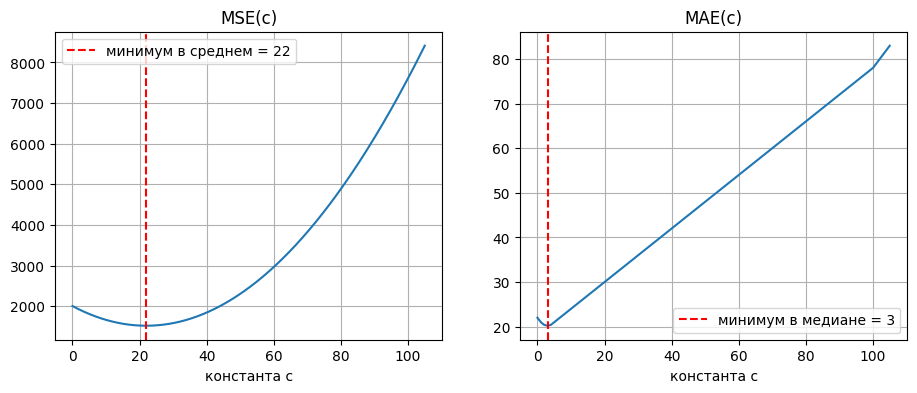

In [28]:
v = np.array([1, 2, 3, 4, 100.])
c_grid = np.linspace(0, 105, 1000)
mse_c = [np.mean((v - c) ** 2) for c in c_grid]
mae_c = [np.mean(np.abs(v - c)) for c in c_grid]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(c_grid, mse_c); ax1.axvline(v.mean(), color="r", ls="--", label=f"минимум в среднем = {v.mean():.0f}")
ax1.set_title("MSE(c)"); ax1.set_xlabel("константа c"); ax1.legend()
ax2.plot(c_grid, mae_c); ax2.axvline(np.median(v), color="r", ls="--", label=f"минимум в медиане = {np.median(v):.0f}")
ax2.set_title("MAE(c)"); ax2.set_xlabel("константа c"); ax2.legend()
plt.show()

**MSE «ориентируется» на среднее** (его тянет за выброс 100), **MAE — на медиану** (выброс почти не влияет). Это ещё одна причина, почему MAE устойчивее к выбросам. (Заметьте, что MAE — негладкая функция, как и $|w|$ в LASSO: у неё в нуле излом.)

#### [$R^2$ (Коэффициент детерминации)](https://scikit-learn.org/dev/modules/generated/sklearn.metrics.r2_score.html)

Коэффициент детерминации — это доля дисперсии зависимой переменной, объясняемая рассматриваемой моделью.

$$R^2 = 1 - \frac{\sum_{i=1}^{m} (y_i - a(x_i))^2}{\sum_{i=1}^{m} (y_i - \overline{y})^2} = 1 - \frac{\sigma^2}{\sigma_y^2}$$

где $\sigma^2$ — условная (по признакам $x$) дисперсия зависимой переменной.

Фактически, данная мера качества — это нормированная среднеквадратичная ошибка. Если она близка к единице, то модель хорошо объясняет данные, если же она близка к нулю, то прогнозы сопоставимы по качеству с константным предсказанием. На новых данных она может быть и **отрицательной**: модель хуже константы.

In [29]:
print(f"предсказание = среднему:     R² = {r2_score(y_wear, np.full(6, y_wear.mean())):.3f}")
print(f"модель из примера выше (B):  R² = {r2_score(y_wear, pred_B):.3f}")
print(f"модель, которая всё портит:  R² = {r2_score(y_wear, y_wear[::-1]):.3f}")

предсказание = среднему:     R² = 0.000
модель из примера выше (B):  R² = 0.907
модель, которая всё портит:  R² = -1.571


#### Процентные метрики: сюжет про склад запчастей

Подшипники на станках нужно вовремя менять, и для этого на складе нужны запчасти. Мы прогнозируем недельный спрос на две позиции. Одна — *ходовой подшипник*, который уходит сотнями; другая — *редкий уплотнитель*, который уходит единицами.

#### [MAPE](https://scikit-learn.org/dev/modules/generated/sklearn.metrics.mean_absolute_percentage_error.html)

Это коэффициент, не имеющий размерности, с очень простой интерпретацией. Его можно измерять в долях или процентах. Если у вас получилось, например, что MAPE=11.4%, то это говорит о том, что ошибка составила 11,4% от фактических значений. Основная проблема данной ошибки — нестабильность: при $y_i \to 0$ она взрывается, а при $y_i = 0$ не определена.

$$ MAPE(y, \hat{y}) = \frac{1}{m} \sum_{i=1}^m \frac{|y_i - a(x_i)|}{|y_i|} $$

#### SMAPE

Symmetric MAPE: знаменатель — «среднее» между фактом и прогнозом, поэтому нулевой факт не ломает формулу (значение лежит в $[0, 2]$).

$$ SMAPE(y, \hat{y}) = \frac{1}{m} \sum_{i=1}^m \frac{2 |y_i - a(x_i)|}{|y_i| + |a(x_i)|} $$

#### WAPE

Weighted APE: суммарная абсолютная ошибка, поделённая на суммарный факт. Ошибки взвешиваются по объёму спроса, поэтому большие позиции весят больше, а малые не «взрывают» метрику.

$$ WAPE(y, \hat{y}) = \frac{\sum_{i=1}^m | y_i - a(x_i) |}{\sum_{i=1}^m | y_i | } $$

In [30]:
# 6 недель: недельный спрос (факт) и прогноз
bearing_y = np.array([980, 1020, 1000, 950, 1050, 1000]);  bearing_p = np.array([1060, 940, 1005, 1030, 960, 1090])
seal_y    = np.array([2, 3, 1, 2, 4, 2]);                  seal_p    = np.array([3, 2, 2, 4, 3, 1])

def mape(y, p):  return np.mean(np.abs(y - p) / np.abs(y))
def smape(y, p): return np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p)))
def wape(y, p):  return np.sum(np.abs(y - p)) / np.sum(np.abs(y))

all_y, all_p = np.r_[bearing_y, seal_y], np.r_[bearing_p, seal_p]
rows = {"ходовой подшипник": (bearing_y, bearing_p), "редкий уплотнитель": (seal_y, seal_p), "обе позиции вместе": (all_y, all_p)}
pd.DataFrame({k: {"MAE (шт.)": mean_absolute_error(*v), "MAPE": mape(*v), "SMAPE": smape(*v), "WAPE": wape(*v)}
              for k, v in rows.items()}).T.style.format({"MAE (шт.)": "{:.1f}", "MAPE": "{:.1%}", "SMAPE": "{:.1%}", "WAPE": "{:.1%}"})

,MAE (шт.),MAPE,SMAPE,WAPE
ходовой подшипник,70.8,7.1%,7.0%,7.1%
редкий уплотнитель,1.2,59.7%,51.4%,50.0%
обе позиции вместе,36.0,33.4%,29.2%,7.2%


- По отдельности: на ходовой позиции все процентные метрики ~7%, и ошибка в 70 штук — это нормально. На редкой позиции ошибка в 1–2 штуки, но в процентах это 50–60%.
- *Вместе:* MAPE (33%) почти целиком определяется редкой позицией, потому что считает среднее по *строкам* таблицы. WAPE (~7%) взвешивает ошибки по объёму и отражает то, что **в штуках** мы промахнулись мало. Какая метрика «правильная» — вопрос бизнес-постановки: если важна каждая позиция одинаково — MAPE; если важны объёмы — WAPE.


### Что выбрать? (шпаргалка)

| Ситуация | Что смотреть |
|---|---|
| Классы сбалансированы, цена ошибок одинакова | accuracy |
| Редкий положительный класс | precision, recall, F1 / $F_\beta$, PR-кривая и AP; accuracy — нет |
| Пропуск дороже ложной тревоги (или наоборот) | $F_\beta$ с нужным $\beta$, выбор порога по precision/recall |
| Важен порядок объектов, баланс умеренный | ROC-AUC |
| Важна калибровка вероятностей | log-loss |
| Много классов, редкие классы важны | macro-усреднение (и classification_report) |
| Много классов, важен каждый объект | micro-усреднение (= accuracy) |
| Регрессия, большие ошибки недопустимы | MSE / RMSE |
| Регрессия, есть выбросы | MAE |
| Нужна «безразмерная» метрика | $R^2$, WAPE; MAPE — только если факт не бывает около нуля |

## Ссылки

**Регуляризация и оптимизация**
- [Методы Оптимизации, ВМК МГУ, Субдифференциалы](http://www.machinelearning.ru/wiki/images/e/e5/MOMO18_Seminar10.pdf)
- [Проксимальный градиентный метод. Проксимальный оператор и его свойства. МФТИ 2024](https://youtu.be/K014nmjb-d8?si=deGPhQUivm3Ulk4q)
- [Проксимальные методы](https://education.yandex.ru/handbook/ml/article/proksimalnye-metody)
- [Методы оптимизации в машинном и глубоком обучении. От простого к сложному](https://habr.com/ru/articles/813221/)
- [Полезный сайт по оптимизации](https://fmin.xyz/)
- [FISTA](https://www.ceremade.dauphine.fr/~carlier/FISTA)
- [Линейные модели](https://education.yandex.ru/handbook/ml/article/linear-models)
- [Регуляризация](https://neerc.ifmo.ru/wiki/index.php?title=%D0%A0%D0%B5%D0%B3%D1%83%D0%BB%D1%8F%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F)
- [Линейная регрессия. Основная идея, модификации и реализация с нуля на Python](https://habr.com/ru/articles/804135/)
- [Подбор гиперпараметров](https://education.yandex.ru/handbook/ml/article/podbor-giperparametrov)
- [Подбор гиперпараметров ML-модели с помощью HYPEROPT](https://habr.com/ru/articles/542624/)

**Метрики**
- [Метрики в задачах машинного обучения](https://habr.com/ru/companies/ods/articles/328372/)
- [Метрики классификации и регрессии](https://education.yandex.ru/handbook/ml/article/metriki-klassifikacii-i-regressii)
- [AUC ROC (площадь под кривой ошибок)](https://alexanderdyakonov.wordpress.com/2017/07/28/auc-roc-%D0%BF%D0%BB%D0%BE%D1%89%D0%B0%D0%B4%D1%8C-%D0%BF%D0%BE%D0%B4-%D0%BA%D1%80%D0%B8%D0%B2%D0%BE%D0%B9-%D0%BE%D1%88%D0%B8%D0%B1%D0%BE%D0%BA/)
- [Метрики качества. Часть 1. Функции ошибки в задаче регрессии](https://github.com/Dyakonov/PZAD/blob/master/2020/PZAD2020_031err_regression_10n.pdf)
- [Метрики качества. Часть 2. Чёткая бинарная классификации](https://github.com/Dyakonov/PZAD/blob/master/2020/PZAD2020_032err_classification_20n.pdf)